In [ ]:
import os
import pandas as pd
from pandas import DataFrame
import glob
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from tqdm import tqdm
import time
import umap
from sklearn.decomposition import PCA
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import DBSCAN
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

In [ ]:
# Paths are relative to the project folder: inputs in data/, files written by
# earlier notebooks in results/, figures in figures/.
DATA_DIR = 'data'
RESULTS_DIR = 'results'
FIGURE_DIR = 'figures'

# Input files
DECONV_DIR = f'{DATA_DIR}/AML_high_res_deconv'
HIRES_GLOB = f'{DECONV_DIR}/**/CIBERSORTxHiRes_NA_*.txt'
BULK_MATRIX = f'{DECONV_DIR}/BULK_AML_CIBERSORTX.txt'
DIST_DF = f'{RESULTS_DIR}/dist_df.csv'
NUM_OF_CELLS = f'{DATA_DIR}/num_of_cells.csv'
os.makedirs(FIGURE_DIR, exist_ok=True)

In [3]:
path = HIRES_GLOB

filenames = glob.glob(path)

annotations = {}
data_records = {}

start_time = time.time()

list_annot = []
list_df = []

for i in tqdm(filenames):
    df = pd.read_csv(i, sep='\t', index_col=0).drop(['AML1', 'AML2', 'AML3'], axis=1)
    cell_type = i.split('CIBERSORTxHiRes_NA_')[-1].split('_Window20')[0]
    sc_ref = i.split('deconv/')[-1].split('/CIBERSORTxHiRes_NA')[0]
    annot_df = df.columns.to_series().str.split('_', expand=True).reset_index()
    annot_df.columns = ['orig_name', 'pat_id', 'refrac_group']
    annot_df['cell_type'] = cell_type
    annot_df['single_cell_reference'] = sc_ref
    annot_df.index = annot_df['pat_id'] + '_' + annot_df['single_cell_reference'] + '_' + annot_df['cell_type']
    if list(set(df.columns == annot_df.orig_name))[0] == True:
        df.columns = annot_df.index
    else:
        print('Failure')
    list_df.append(df)
    list_annot.append(annot_df)
    
elapsed = time.time() - start_time
print(f"Completed in {elapsed:.2f} seconds")

100%|██████████| 595/595 [05:22<00:00,  1.85it/s]

Completed in 322.45 seconds


In [4]:
full_annot = pd.concat(list_annot, axis=0)

In [5]:
full_data = pd.concat(list_df, axis=1)

In [7]:
fvar = full_data.var(axis=1)

In [8]:
full_data = full_data.loc[fvar > 1]

In [9]:
subset_np = full_data.to_numpy()
subset_np = np.nan_to_num(subset_np, nan=1)
full_data = pd.DataFrame(subset_np, index=full_data.index, columns=full_data.columns)

In [11]:
X = full_data.T

svd = TruncatedSVD(n_components=500)
X_pca = svd.fit_transform(X)

In [12]:
reducer = umap.UMAP(n_neighbors=50, min_dist=0.1, metric='cosine')
embedding = reducer.fit_transform(X_pca)  # returns (81515, 2)

/mnt/home/leshchi4/.local/lib/python3.11/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


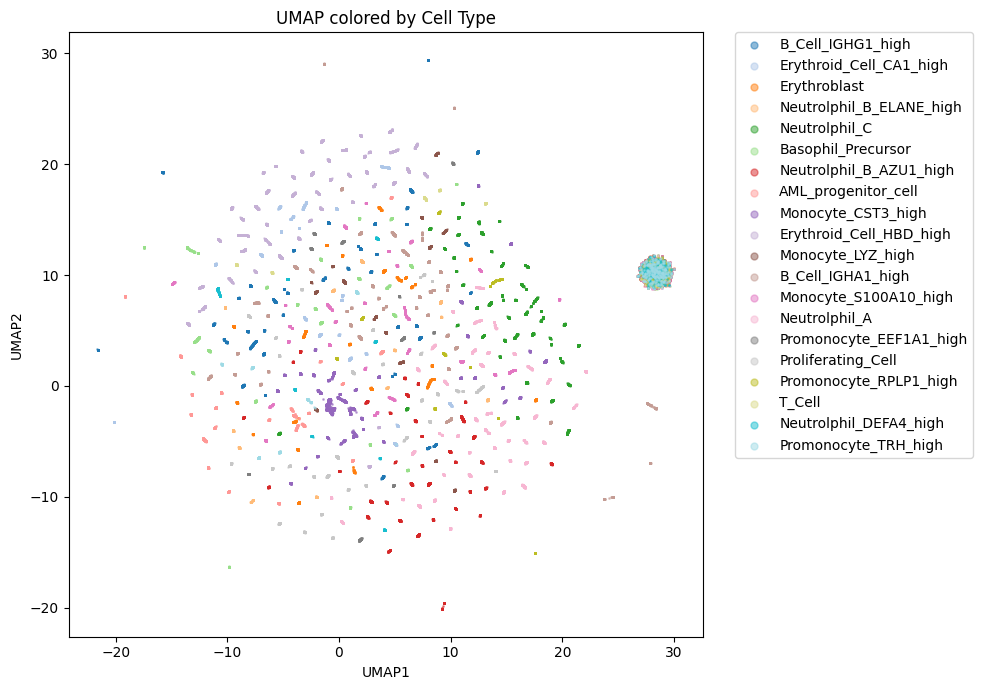

In [14]:
colors = full_annot['cell_type']  

unique_groups = colors.unique()
palette = sns.color_palette('tab20', n_colors=len(unique_groups))
lut = dict(zip(unique_groups, palette))

fig, ax = plt.subplots(figsize=(10,7))

for group in unique_groups:
    idx = colors == group
    ax.scatter(embedding[idx,0], embedding[idx,1], c=[lut[group]], label=group, s=1, alpha=0.5)

ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title('UMAP colored by Cell Type')
ax.legend(markerscale=5, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.show()

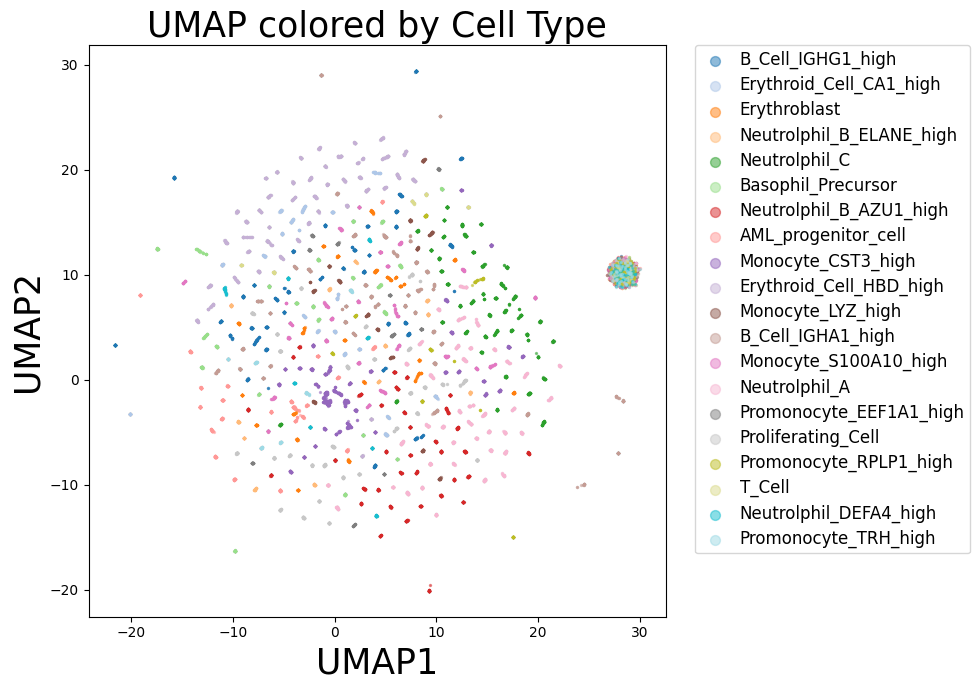

In [15]:
colors = full_annot['cell_type']
unique_groups = colors.unique()
palette = sns.color_palette('tab20', n_colors=len(unique_groups))
lut = dict(zip(unique_groups, palette))

fig, ax = plt.subplots(figsize=(10,7))

# Plot with rasterization and optional downsampling per group
sample_frac = 0.2  # adjust 0.1-1.0 depending on dataset size

for group in unique_groups:
    idx = colors == group
    group_coords = embedding[idx, :]

    # Optional downsampling to reduce points
    if sample_frac < 1.0:
        n_sample = int(len(group_coords) * sample_frac)
        if n_sample > 0:
            sampled_idx = np.random.choice(len(group_coords), n_sample, replace=False)
            group_coords = group_coords[sampled_idx]

    ax.scatter(group_coords[:,0], group_coords[:,1],
               c=[lut[group]], label=group,
               s=2, alpha=0.5, rasterized=True)  # rasterized points = smaller PDF

# Labels and title
ax.set_xlabel('UMAP1', fontsize=25, fontname='DejaVu Sans')
ax.set_ylabel('UMAP2', fontsize=25, fontname='DejaVu Sans')
ax.set_title('UMAP colored by Cell Type', fontsize=25, fontname='DejaVu Sans')

# Legend
legend = ax.legend(markerscale=5, bbox_to_anchor=(1.05, 1),
                   loc='upper left', borderaxespad=0.)
for text in legend.get_texts():
    text.set_fontsize(12)
    text.set_fontname('DejaVu Sans')

plt.tight_layout()

plt.savefig(f'{FIGURE_DIR}/figure1_celltype.svg', dpi=300)  # editable vector text
plt.show()

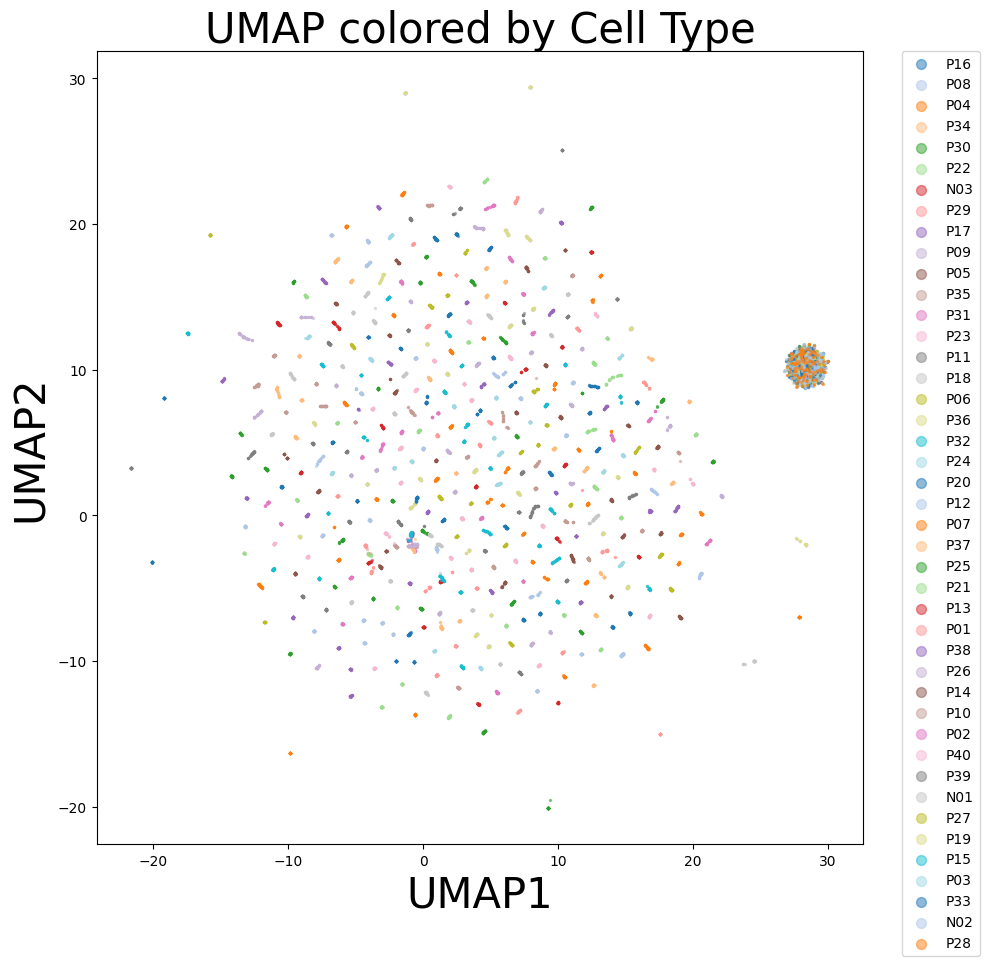

In [16]:
colors = full_annot['single_cell_reference']
unique_groups = colors.unique()
palette = sns.color_palette('tab20', n_colors=len(unique_groups))
lut = dict(zip(unique_groups, palette))

fig, ax = plt.subplots(figsize=(10,10))

# Plot with rasterization and optional downsampling per group
sample_frac = 0.2  # adjust 0.1-1.0 depending on dataset size

for group in unique_groups:
    idx = colors == group
    group_coords = embedding[idx, :]

    # Optional downsampling to reduce points
    if sample_frac < 1.0:
        n_sample = int(len(group_coords) * sample_frac)
        if n_sample > 0:
            sampled_idx = np.random.choice(len(group_coords), n_sample, replace=False)
            group_coords = group_coords[sampled_idx]

    ax.scatter(group_coords[:,0], group_coords[:,1],
               c=[lut[group]], label=group,
               s=2, alpha=0.5, rasterized=True)  # rasterized points = smaller PDF

# Labels and title
ax.set_xlabel('UMAP1', fontsize=30, fontname='DejaVu Sans')
ax.set_ylabel('UMAP2', fontsize=30, fontname='DejaVu Sans')
ax.set_title('UMAP colored by Cell Type', fontsize=30, fontname='DejaVu Sans')

# Legend
ax.legend(markerscale=5, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout()

plt.savefig(f'{FIGURE_DIR}/figure1_pat.svg', dpi=300)  # editable vector text
plt.show()

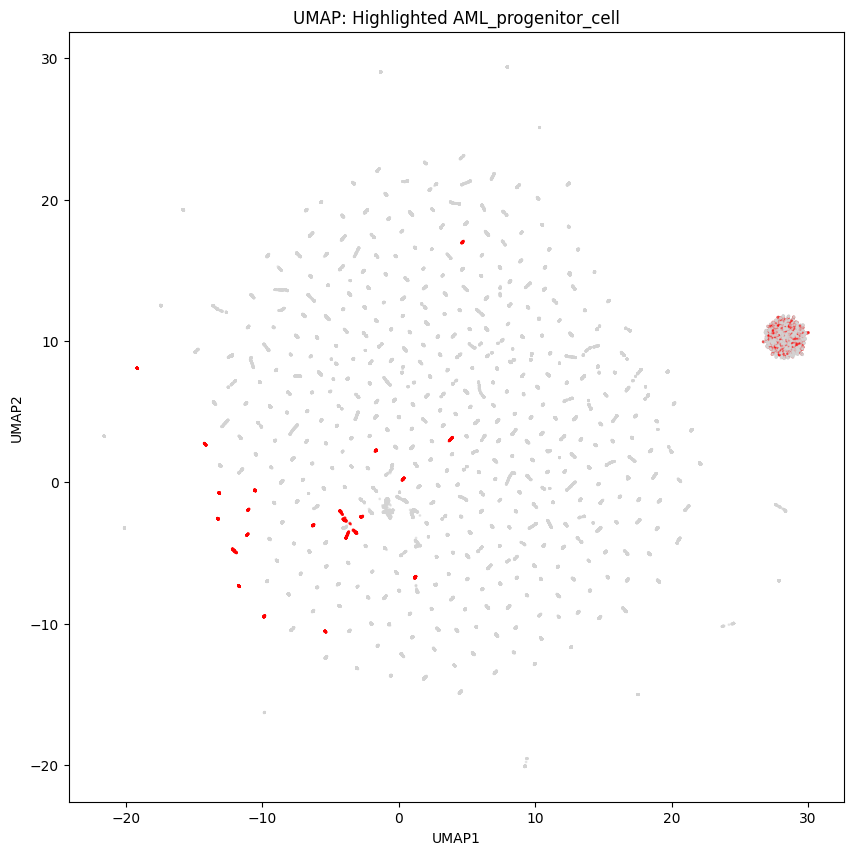

In [18]:
colors = full_annot['cell_type']  
 
unique_groups = colors.unique()
palette = sns.color_palette('tab20', n_colors=len(unique_groups))
lut = dict(zip(unique_groups, palette))

fig, ax = plt.subplots(figsize=(10,10))

highlight = 'AML_progenitor_cell'
highlight_color = 'red'
default_color = 'lightgrey'

colors_mapped = colors.apply(lambda x: highlight_color if x == highlight else default_color)

ax.scatter(embedding[:,0], embedding[:,1], c=colors_mapped, s=1, alpha=0.5)

ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title(f'UMAP: Highlighted {highlight}')
plt.show()

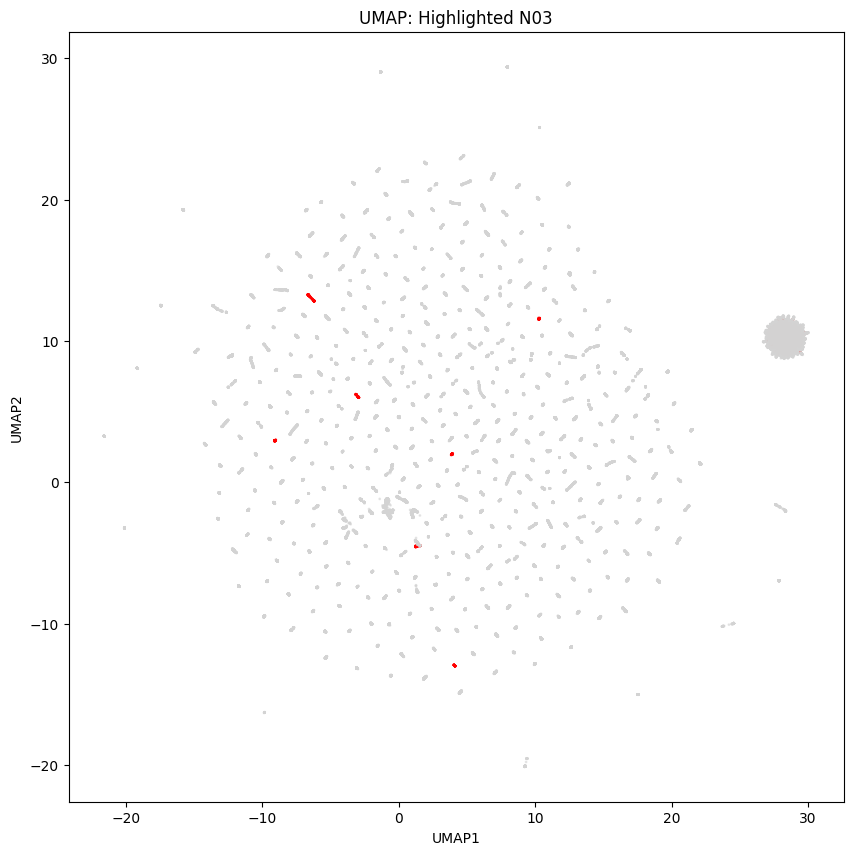

In [19]:
colors = full_annot['single_cell_reference']  
 
unique_groups = colors.unique()
palette = sns.color_palette('tab20', n_colors=len(unique_groups))
lut = dict(zip(unique_groups, palette))

fig, ax = plt.subplots(figsize=(10,10))

highlight = 'N03'
highlight_color = 'red'
default_color = 'lightgrey'

colors_mapped = colors.apply(lambda x: highlight_color if x == highlight else default_color)

ax.scatter(embedding[:,0], embedding[:,1], c=colors_mapped, s=1, alpha=0.5)

ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title(f'UMAP: Highlighted {highlight}')
plt.savefig(f'{FIGURE_DIR}/figure3_pat.pdf')
plt.show()

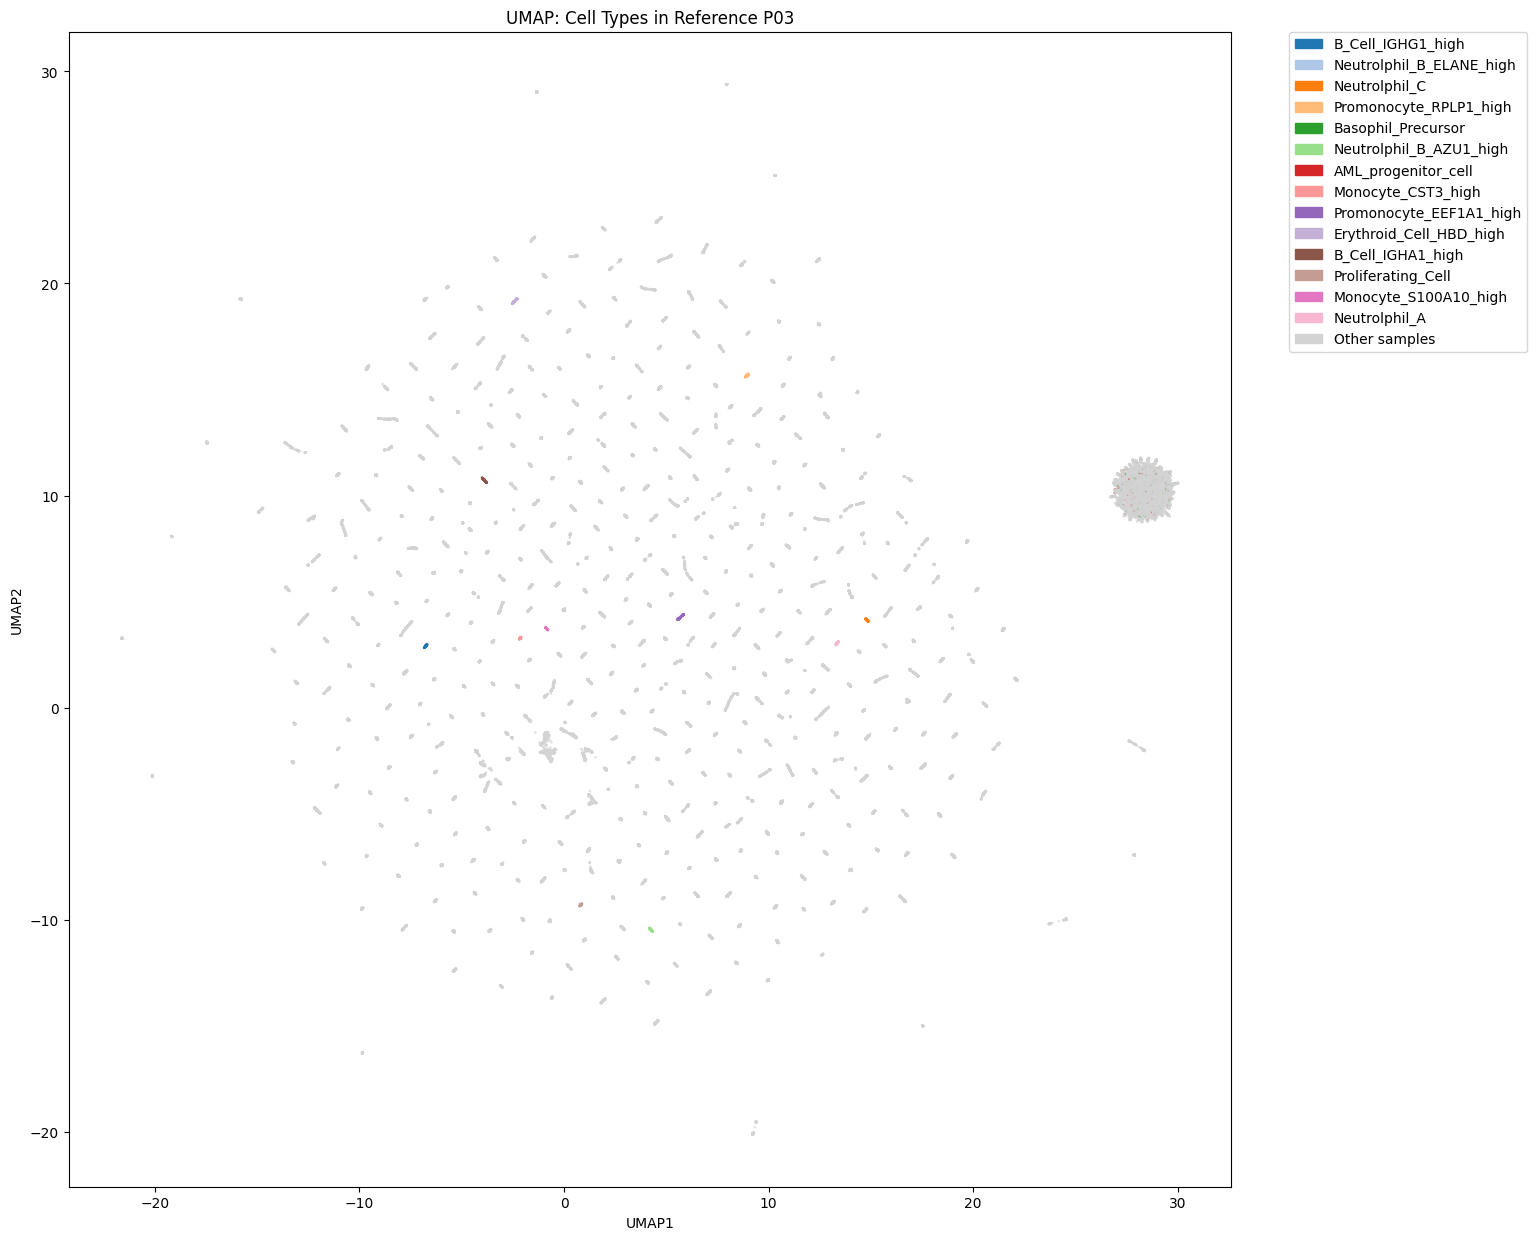

In [20]:
single_cell_ref = full_annot['single_cell_reference']
cell_types = full_annot['cell_type']

highlight_ref = 'P03'  # reference to highlight

colors_mapped = np.array(['lightgrey'] * len(cell_types))  # default gray

# Mask for cells in the highlighted reference
ref_mask = single_cell_ref == highlight_ref

# Get all cell types present in this reference
ref_cell_types = cell_types[ref_mask].unique()

# Generate palette for these cell types
palette = sns.color_palette('tab20', n_colors=len(ref_cell_types))
palette_hex = [mcolors.to_hex(c) for c in palette]
lut = dict(zip(ref_cell_types, palette_hex))

# Assign colors by cell type for cells within the highlighted reference
for ct in ref_cell_types:
    idx = ref_mask & (cell_types == ct)
    colors_mapped[idx] = lut[ct]

# Plot
fig, ax = plt.subplots(figsize=(15,15))
ax.scatter(embedding[:,0], embedding[:,1], c=colors_mapped, s=1, alpha=0.5)

# Legend
legend_handles = [mpatches.Patch(color=lut[ct], label=ct) for ct in ref_cell_types]
legend_handles.append(mpatches.Patch(color='lightgrey', label='Other samples'))

ax.legend(handles=legend_handles, markerscale=5, bbox_to_anchor=(1.05, 1),
          loc='upper left', borderaxespad=0.)

ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title(f'UMAP: Cell Types in Reference {highlight_ref}')
plt.savefig(f'{FIGURE_DIR}/figure4_cellsinpat.pdf')
plt.show()

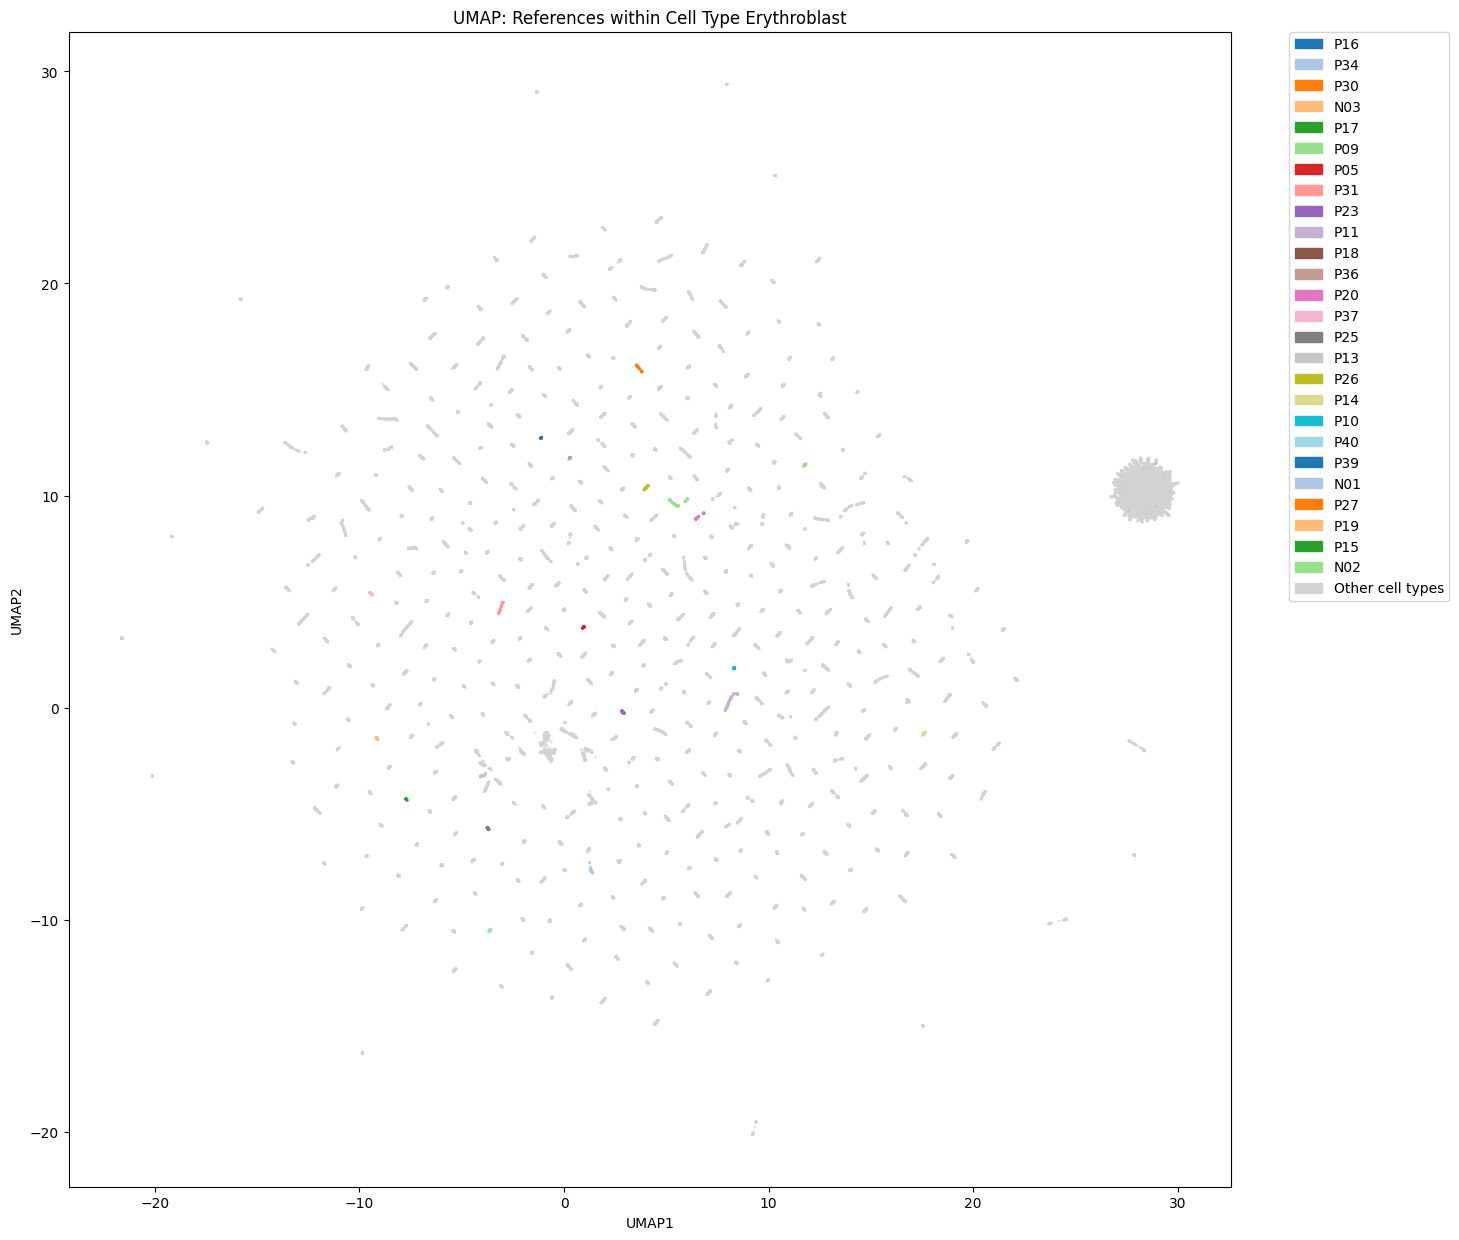

In [21]:
single_cell_ref = full_annot['single_cell_reference']
cell_types = full_annot['cell_type']

highlight_cell_type = 'Erythroblast'  # cell type to highlight

# Initialize colors: all points start as light grey
colors_mapped = np.array(['lightgrey'] * len(cell_types))

# Boolean mask for cells of the highlighted cell type
cell_type_mask = (cell_types == highlight_cell_type)

# Get all references present in this cell type
refs_in_cell_type = single_cell_ref[cell_type_mask].unique()

# Create a color palette for these references
palette = sns.color_palette('tab20', n_colors=len(refs_in_cell_type))
palette_hex = [mcolors.to_hex(c) for c in palette]
lut = dict(zip(refs_in_cell_type, palette_hex))

# Map colors to the single_cell_reference for the highlighted cell type
colors_mapped[cell_type_mask] = single_cell_ref[cell_type_mask].map(lut)

# Plot
fig, ax = plt.subplots(figsize=(15,15))
ax.scatter(embedding[:,0], embedding[:,1], c=colors_mapped, s=1, alpha=0.5)

# Create legend for references in the highlighted cell type
legend_handles = [mpatches.Patch(color=lut[ref], label=ref) for ref in refs_in_cell_type]
legend_handles.append(mpatches.Patch(color='lightgrey', label='Other cell types'))

ax.legend(handles=legend_handles, markerscale=5, bbox_to_anchor=(1.05, 1),
          loc='upper left', borderaxespad=0.)

ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title(f'UMAP: References within Cell Type {highlight_cell_type}')
plt.savefig(f'{FIGURE_DIR}/figure5_patincell.pdf')
plt.show()

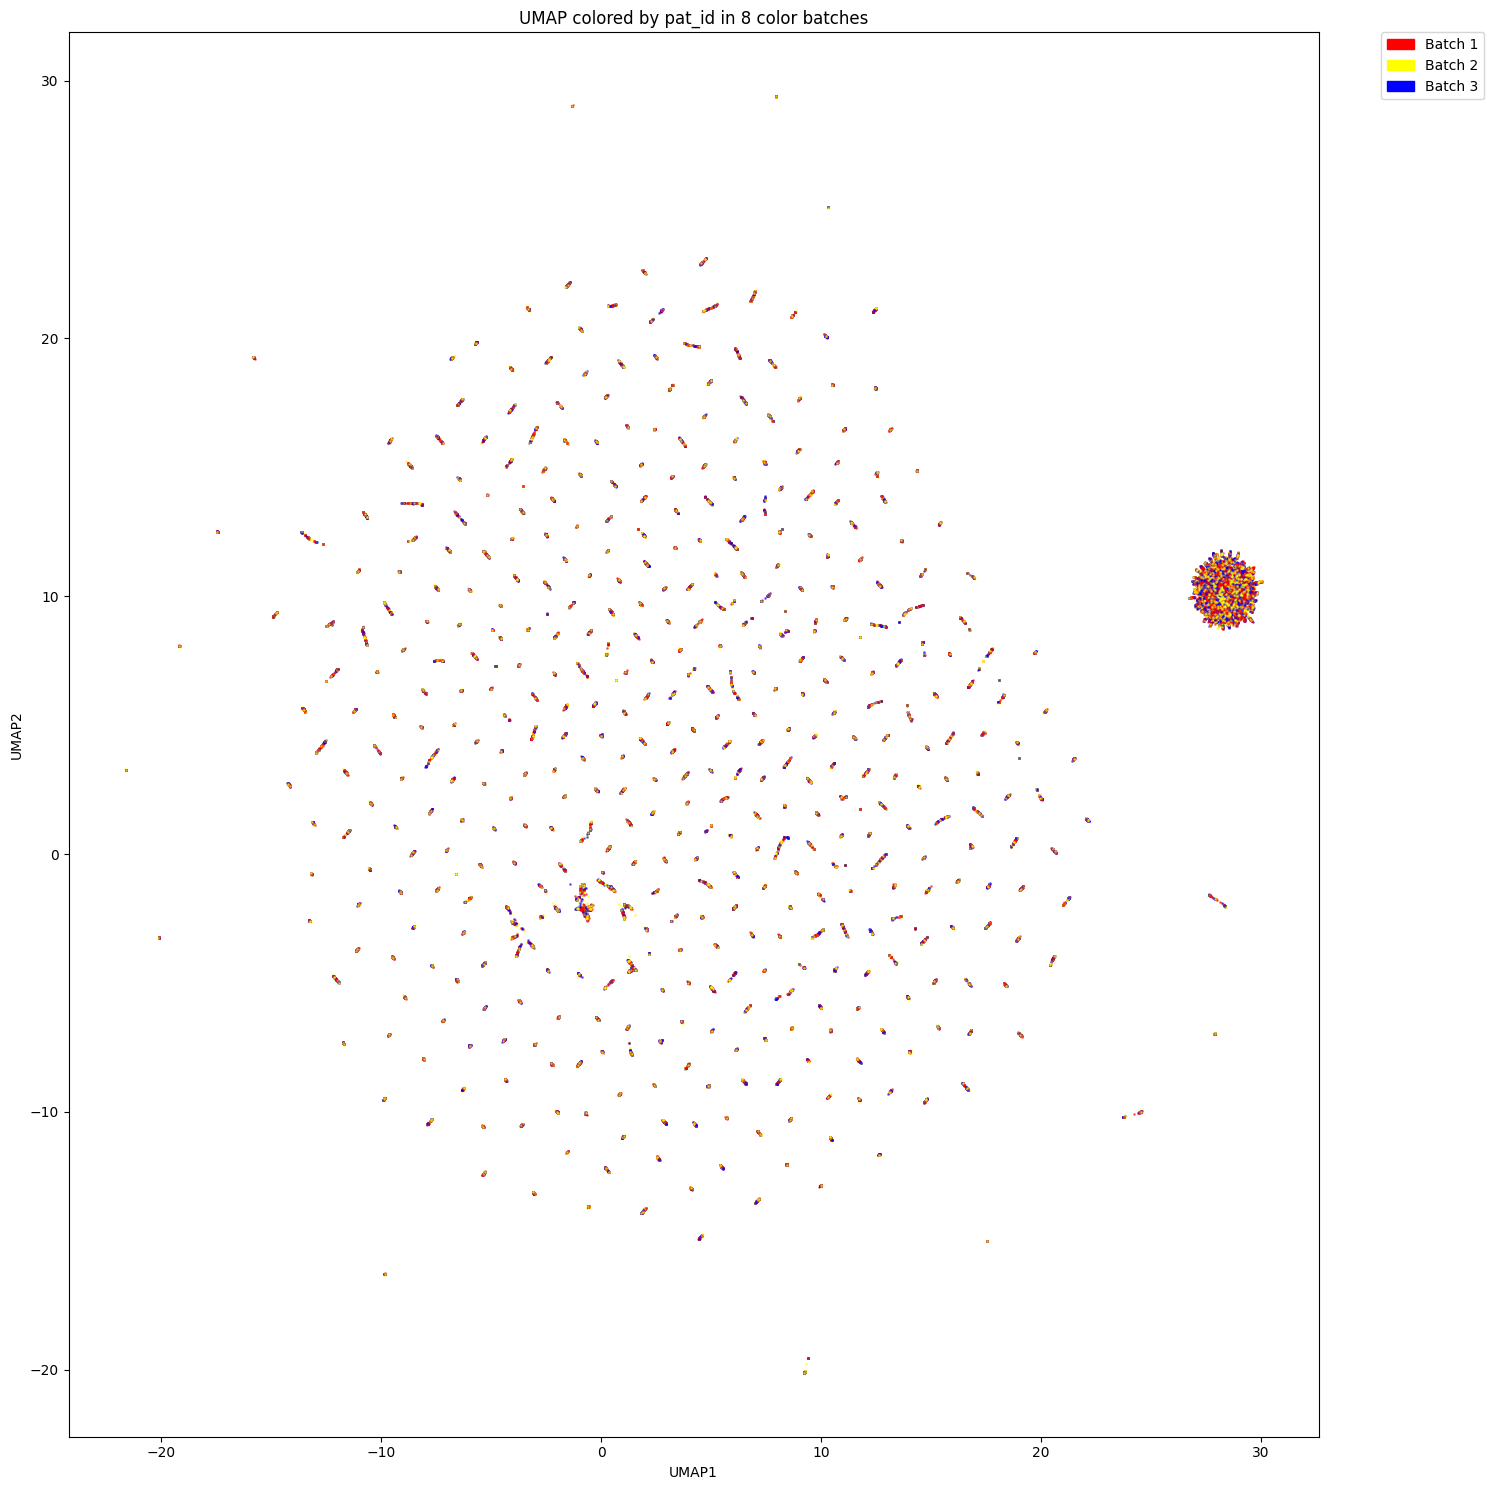

In [23]:
colors = full_annot['pat_id']
unique_groups = colors.unique()

num_color_groups = 3
palette = ['#FF0000', '#FFFF00', '#0000FF']  # hex codes for red, yellow, blue
lut = {pat_id: palette[i % num_color_groups] for i, pat_id in enumerate(unique_groups)}

fig, ax = plt.subplots(figsize=(15,15))

for group in unique_groups:
    idx = colors == group
    ax.scatter(embedding[idx,0], embedding[idx,1], c=[lut[group]], label=group, s=1, alpha=0.5)

ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title('UMAP colored by pat_id in 8 color batches')

# Optional: To avoid huge legends, show only 8 legend entries representing the batches
batch_labels = [f'Batch {i+1}' for i in range(8)]
batch_handles = [Patch(color=palette[i], label=batch_labels[i]) for i in range(num_color_groups)]

ax.legend(handles=batch_handles, markerscale=5, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure6_patid.pdf')
plt.show()

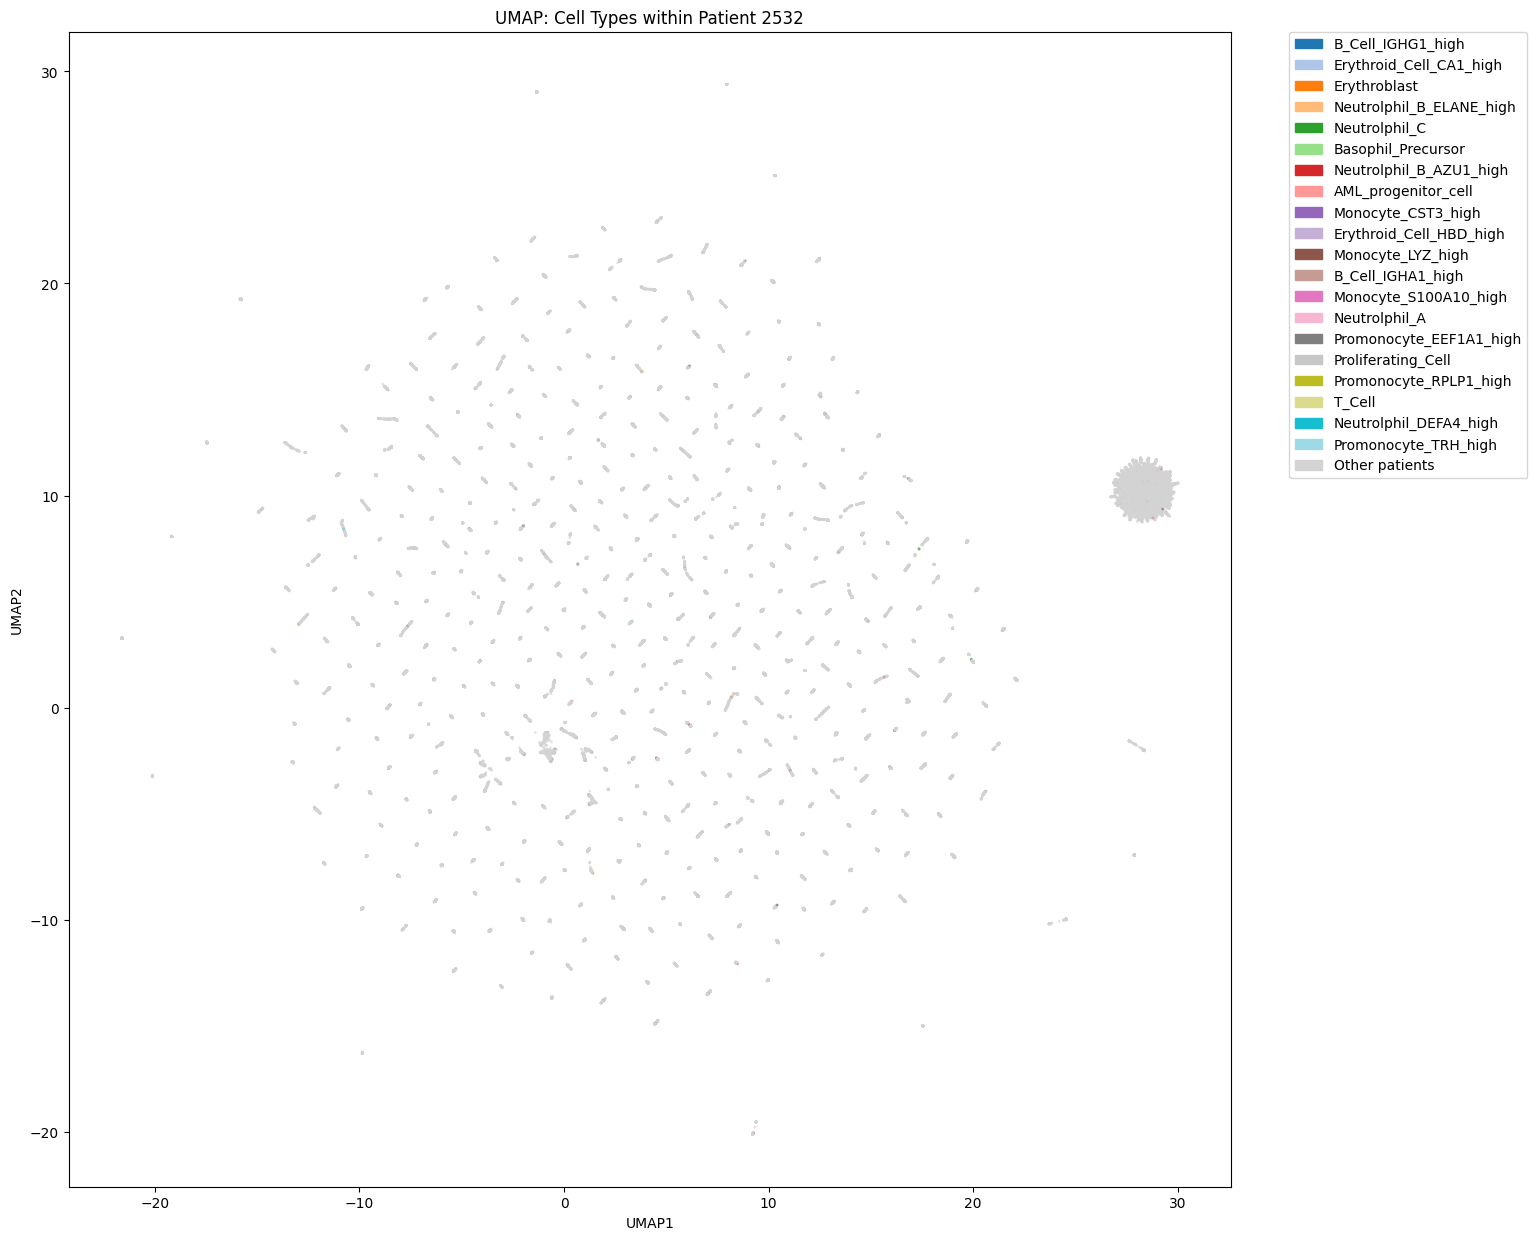

In [24]:
pat_ids = full_annot['pat_id']
cell_types = full_annot['cell_type']

highlight_pat = 2532  # patient ID to highlight

colors_mapped = np.array(['lightgrey'] * len(cell_types))

pat_mask = (pat_ids == str(highlight_pat))

cell_types_in_pat = cell_types[pat_mask].unique()

palette = sns.color_palette('tab20', n_colors=len(cell_types_in_pat))
palette_hex = [mcolors.to_hex(c) for c in palette]  # convert to hex
lut = dict(zip(cell_types_in_pat, palette_hex))

for ct in cell_types_in_pat:
    idx = pat_mask & (cell_types == ct)
    colors_mapped[idx] = lut[ct]  # assign hex string, not RGB tuple

fig, ax = plt.subplots(figsize=(15, 15))
ax.scatter(embedding[:, 0], embedding[:, 1], c=colors_mapped, s=1, alpha=0.5)

legend_handles = [mpatches.Patch(color=lut[ct], label=ct) for ct in cell_types_in_pat]
legend_handles.append(mpatches.Patch(color='lightgrey', label='Other patients'))

ax.legend(handles=legend_handles, markerscale=5, bbox_to_anchor=(1.05, 1),
          loc='upper left', borderaxespad=0.)

ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title(f'UMAP: Cell Types within Patient {highlight_pat}')
plt.show()

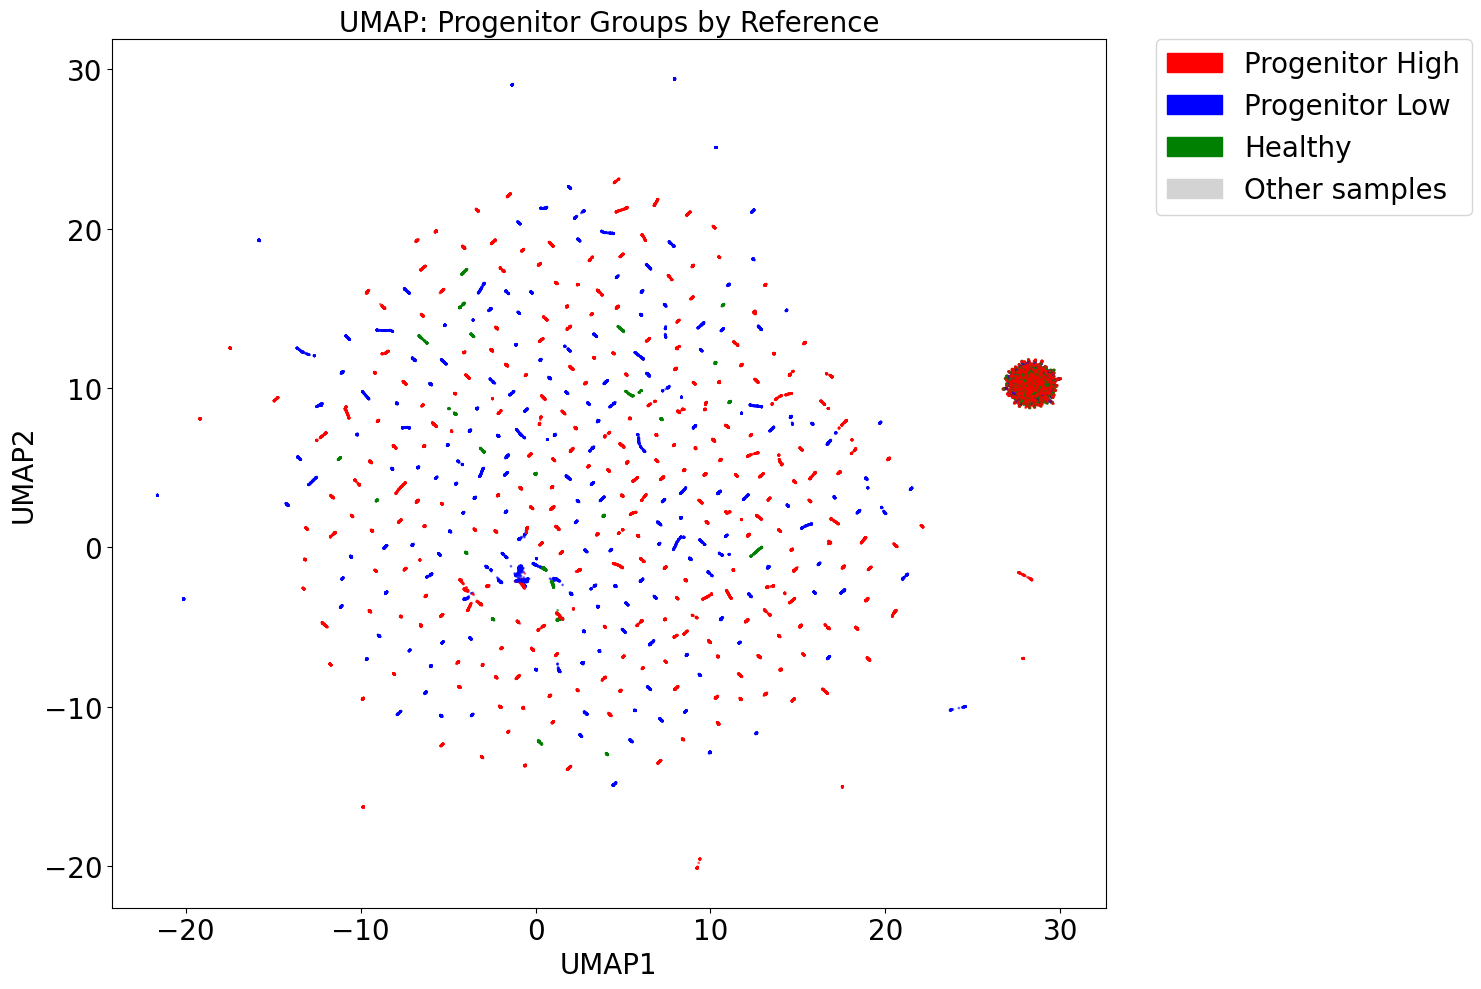

In [26]:
single_cell_ref = full_annot['single_cell_reference']

# Your three groups of references (fill in as needed)
progen_high = ['P14','P02','P08','P07','P12','P21','P38','P24','P29','P03','P22','P05','P06','P09','P01','P04','P19','P33','P28','P20','P30','P15','P37']
progen_low = ['P40','P11','P39','P10','P26','P17','P36','P31','P35','P16','P32','P13','P25','P27','P23','P34','P18']
normal_ref = ['N01', 'N02', 'N03']

colors_mapped = np.array(['lightgrey'] * len(single_cell_ref))  # default gray

# Masks for each group
high_mask = single_cell_ref.isin(progen_high)
low_mask = single_cell_ref.isin(progen_low)
mid_mask = single_cell_ref.isin(normal_ref)

# Assign distinct colors for each group
palette = sns.color_palette(['red', 'blue', 'green'])  # 3 distinct colors
high_color = mcolors.to_hex(palette[0])
low_color = mcolors.to_hex(palette[1])
mid_color = mcolors.to_hex(palette[2])

colors_mapped[high_mask] = high_color
colors_mapped[low_mask] = low_color
colors_mapped[mid_mask] = mid_color

fig, ax = plt.subplots(figsize=(15, 10))
ax.scatter(embedding[:, 0], embedding[:, 1], c=colors_mapped, s=1, alpha=0.5)

# Legend
legend_handles = [
    mpatches.Patch(color=high_color, label='Progenitor High'),
    mpatches.Patch(color=low_color, label='Progenitor Low'),
    mpatches.Patch(color=mid_color, label='Healthy'),
    mpatches.Patch(color='lightgrey', label='Other samples')
]

ax.legend(handles=legend_handles, markerscale=5, bbox_to_anchor=(1.05, 1),
          loc='upper left', borderaxespad=0., fontsize=20)

# Labels and title with larger font
ax.set_xlabel('UMAP1', fontsize=20)
ax.set_ylabel('UMAP2', fontsize=20)
ax.set_title('UMAP: Progenitor Groups by Reference', fontsize=20)

# Tick label sizes
ax.tick_params(axis='both', labelsize=20)

plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure6_progen_hl.pdf')
plt.show()

In [27]:
clustering = DBSCAN(eps=0.5, min_samples=10).fit(embedding)

labels = clustering.labels_

unique_labels, counts = np.unique(labels[labels != -1], return_counts=True)
biggest_cluster_label = unique_labels[np.argmax(counts)]

print(f"Biggest cluster label: {biggest_cluster_label}, size: {counts.max()}")

Biggest cluster label: 2, size: 18084


In [28]:
biggest_cluster_mask = labels == biggest_cluster_label

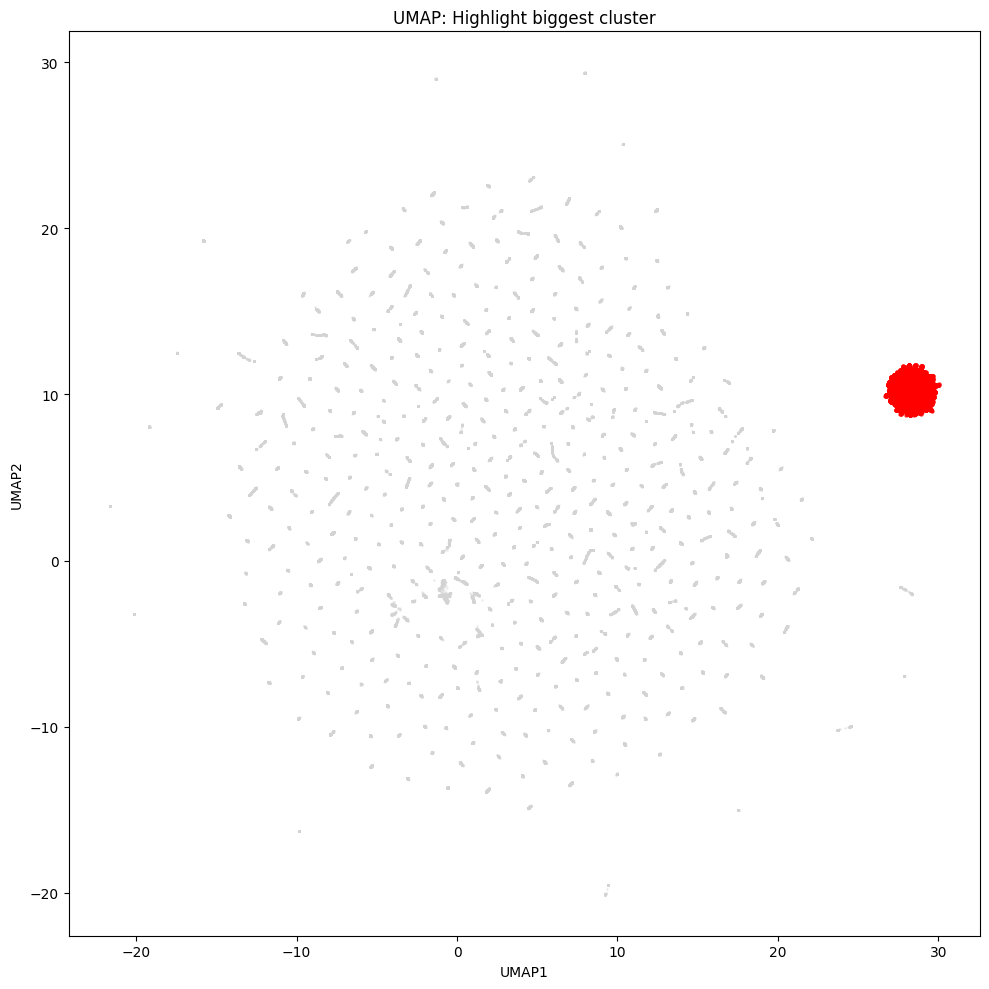

In [29]:
fig, ax = plt.subplots(figsize=(10,10))
ax.scatter(embedding[:, 0], embedding[:, 1], c='lightgrey', s=1, alpha=0.3)
ax.scatter(embedding[biggest_cluster_mask, 0], embedding[biggest_cluster_mask, 1],
           c='red', s=5, alpha=0.7)
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title('UMAP: Highlight biggest cluster')
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure7_bc.pdf')
plt.show()

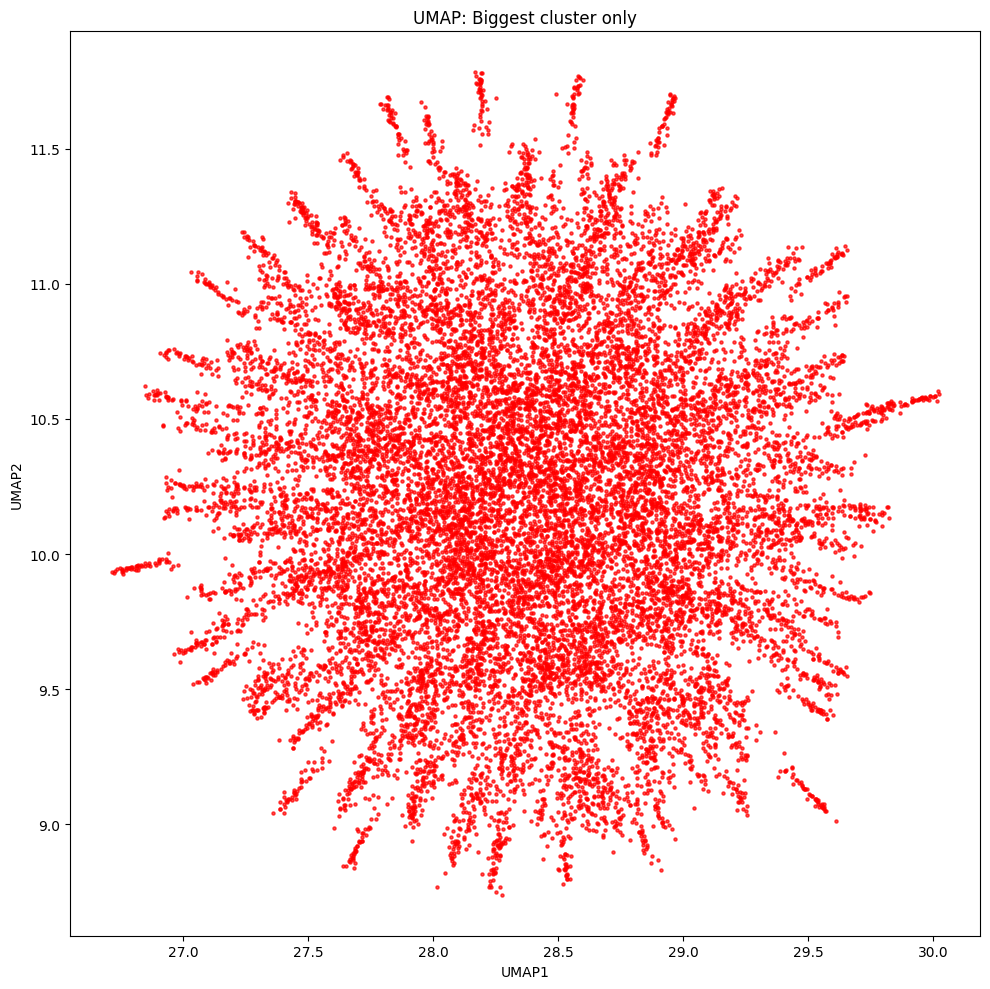

In [30]:
fig, ax = plt.subplots(figsize=(10,10))
ax.scatter(embedding[biggest_cluster_mask, 0], embedding[biggest_cluster_mask, 1],
           c='red', s=5, alpha=0.7)
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title('UMAP: Biggest cluster only')
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure8_bcisolated.pdf')
plt.show()

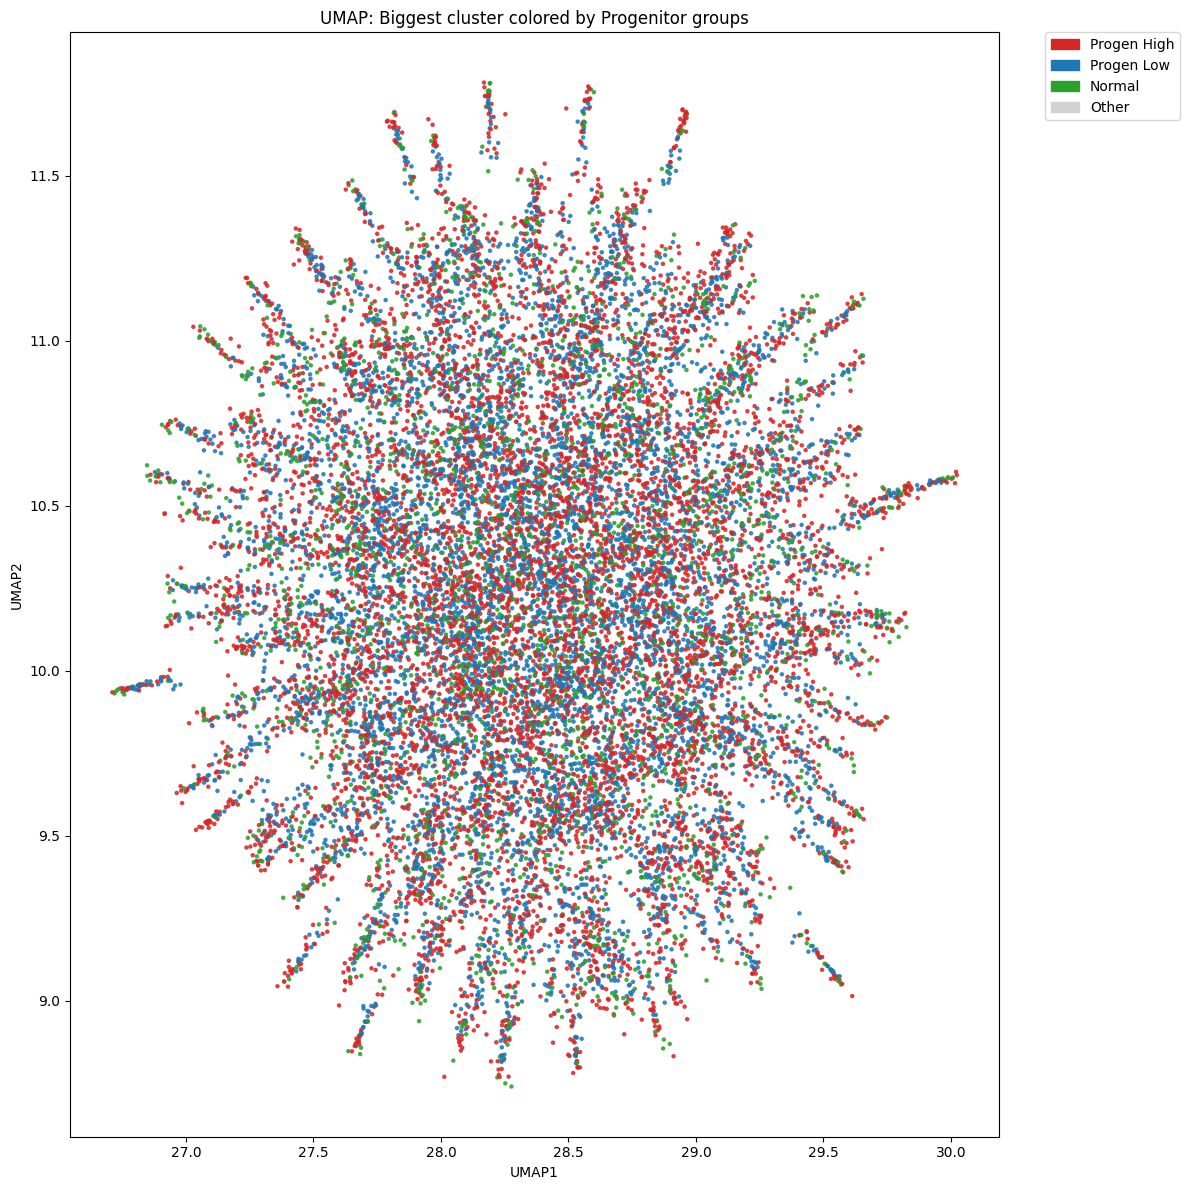

In [31]:
single_cell_ref = full_annot['single_cell_reference'].astype(str)

# Define your groups
progen_high = ['P14','P02','P08','P07','P12','P21','P38','P24','P29','P03','P22','P05','P06','P09','P01','P04','P19','P33','P28','P20','P30','P15','P37']
progen_low = ['P40','P11','P39','P10','P26','P17','P36','P31','P35','P16','P32','P13','P25','P27','P23','P34','P18']
normal_ref = ['N01', 'N02', 'N03']

# 3. Filter only points in biggest cluster
embedding_biggest = embedding[biggest_cluster_mask]
refs_biggest = single_cell_ref[biggest_cluster_mask].reset_index(drop=True)

# 4. Map references in biggest cluster to groups
groups = np.array(['Other'] * len(refs_biggest), dtype=object)
groups[np.isin(refs_biggest, progen_high)] = 'Progen_High'
groups[np.isin(refs_biggest, progen_low)] = 'Progen_Low'
groups[np.isin(refs_biggest, normal_ref)] = 'Normal'

# 5. Assign colors
color_dict = {
    'Progen_High': '#d62728',  # red
    'Progen_Low': '#1f77b4',   # blue
    'Normal': '#2ca02c',       # green
    'Other': 'lightgrey'
}
colors_mapped = np.array([color_dict[g] for g in groups])

# 6. Plot only biggest cluster points colored by group
fig, ax = plt.subplots(figsize=(12, 12))
scatter = ax.scatter(embedding_biggest[:, 0], embedding_biggest[:, 1], c=colors_mapped, s=5, alpha=0.8)

# Legend
legend_handles = [
    mpatches.Patch(color=color_dict['Progen_High'], label='Progen High'),
    mpatches.Patch(color=color_dict['Progen_Low'], label='Progen Low'),
    mpatches.Patch(color=color_dict['Normal'], label='Normal'),
    mpatches.Patch(color=color_dict['Other'], label='Other')
]

ax.legend(handles=legend_handles, markerscale=5, bbox_to_anchor=(1.05, 1),
          loc='upper left', borderaxespad=0.)

ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title('UMAP: Biggest cluster colored by Progenitor groups')
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure9_bc_hl.pdf')
plt.show()

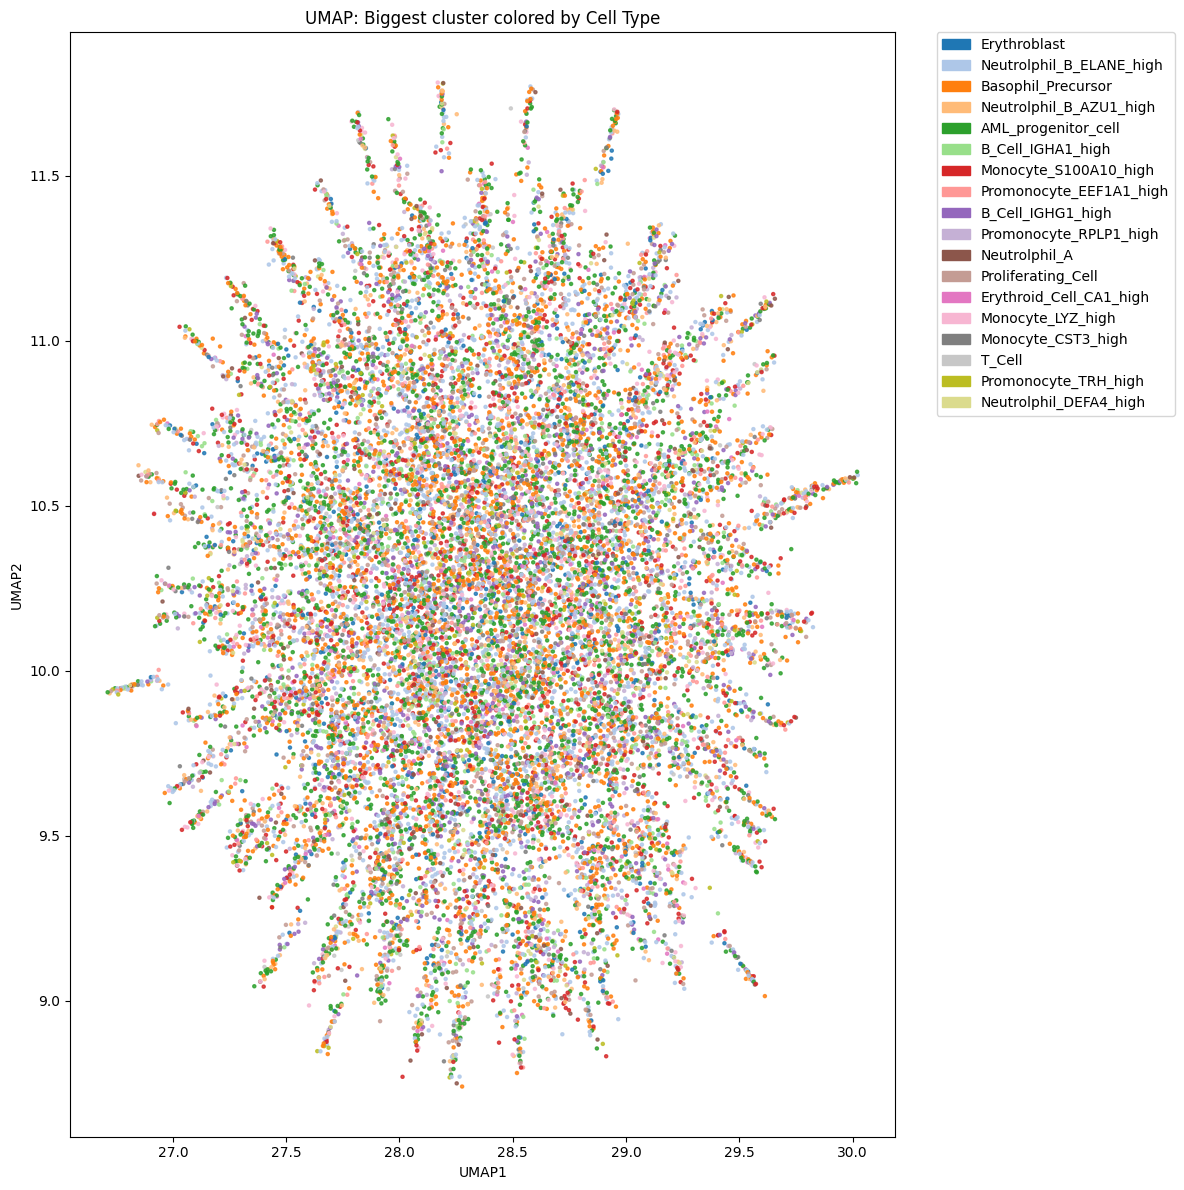

In [32]:
cell_types = full_annot['cell_type'].astype(str)

# Filter only points in biggest cluster
embedding_biggest = embedding[biggest_cluster_mask]
cell_types_biggest = cell_types[biggest_cluster_mask].reset_index(drop=True)

# Get unique cell types in biggest cluster
unique_cell_types = cell_types_biggest.unique()

# Create color palette
palette = sns.color_palette('tab20', n_colors=len(unique_cell_types))
color_dict = dict(zip(unique_cell_types, palette))

# Map colors for points by cell type
colors_mapped = np.array([color_dict[ct] for ct in cell_types_biggest])

# Plot
fig, ax = plt.subplots(figsize=(12, 12))
ax.scatter(embedding_biggest[:, 0], embedding_biggest[:, 1], c=colors_mapped, s=5, alpha=0.8)

# Legend
legend_handles = [mpatches.Patch(color=color_dict[ct], label=ct) for ct in unique_cell_types]
ax.legend(handles=legend_handles, markerscale=5, bbox_to_anchor=(1.05, 1),
          loc='upper left', borderaxespad=0.)

ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title('UMAP: Biggest cluster colored by Cell Type')
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure10_cellbc.pdf')
plt.show()

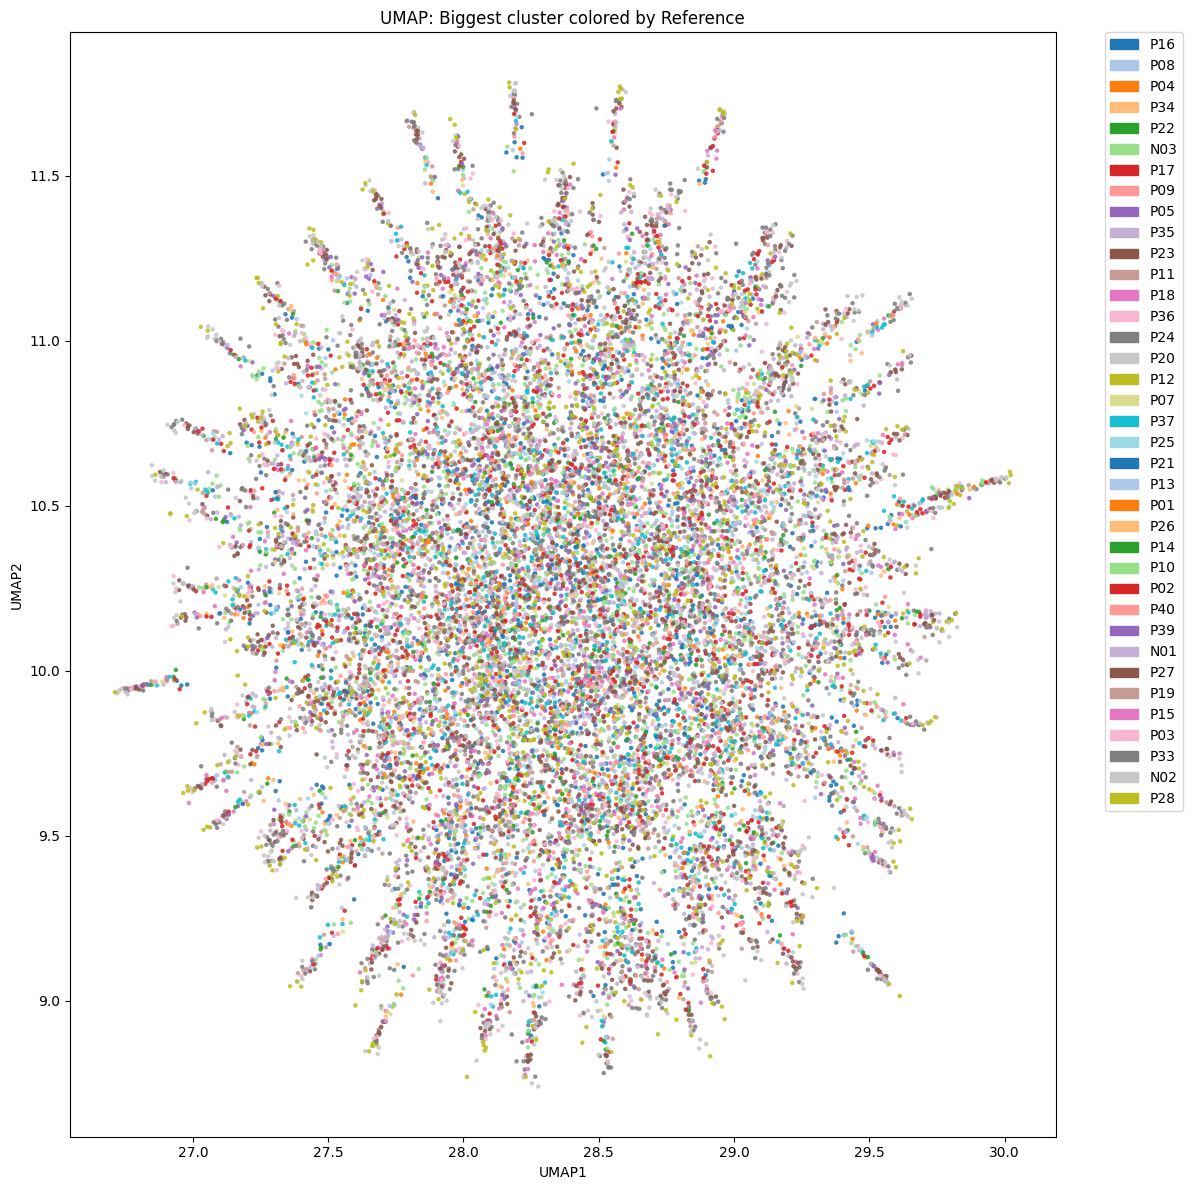

In [33]:
single_cell_ref = full_annot['single_cell_reference'].astype(str)

# Filter only points in biggest cluster
embedding_biggest = embedding[biggest_cluster_mask]
refs_biggest = single_cell_ref[biggest_cluster_mask].reset_index(drop=True)

# Unique references in biggest cluster
unique_refs = refs_biggest.unique()

# Create color palette
palette = sns.color_palette('tab20', n_colors=len(unique_refs))
color_dict = dict(zip(unique_refs, palette))

# Map colors for points by reference
colors_mapped = np.array([color_dict[ref] for ref in refs_biggest])

# Plot
fig, ax = plt.subplots(figsize=(12, 12))
ax.scatter(embedding_biggest[:, 0], embedding_biggest[:, 1], c=colors_mapped, s=5, alpha=0.8)

# Legend
legend_handles = [mpatches.Patch(color=color_dict[ref], label=ref) for ref in unique_refs]
ax.legend(handles=legend_handles, markerscale=5, bbox_to_anchor=(1.05, 1),
          loc='upper left', borderaxespad=0.)

ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
ax.set_title('UMAP: Biggest cluster colored by Reference')
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure11_bcref.pdf')
plt.show()

In [34]:
dist_df = pd.read_csv(DIST_DF, index_col=0)
all_refs = list(set(full_annot['single_cell_reference']))

good_dict = {}

for row in dist_df.index:
    paired_cols = dist_df.loc[row][dist_df.loc[row] < 5].index.tolist()
    good_dict[row] = paired_cols

list_anot_pair = []

for k in all_refs:
    pair_ref = good_dict[k]
    anot_pair = full_annot[full_annot['single_cell_reference'] == k]
    anot_pair = anot_pair[anot_pair['pat_id'].isin(pair_ref)]
    list_anot_pair.append(anot_pair)

good_pairs = pd.concat(list_anot_pair, axis=0)

bad_dict = {}

for row in dist_df.index:
    paired_cols = dist_df.loc[row][dist_df.loc[row] > 60].index.tolist()
    bad_dict[row] = paired_cols

list_anot_pair = []

for k in all_refs:
    try:
        pair_ref = bad_dict[k]
        anot_pair = full_annot[full_annot['single_cell_reference'] == k]
        anot_pair = anot_pair[anot_pair['pat_id'].isin(pair_ref)]
        list_anot_pair.append(anot_pair)
    except:
        continue

bad_pairs = pd.concat(list_anot_pair, axis=0)
print(len(good_pairs), len(bad_pairs), len(full_annot))

good_mask = full_annot.index.isin(good_pairs.index)
bad_mask = full_annot.index.isin(bad_pairs.index)
average_mask = ~(good_mask | bad_mask)

5546 7921 81515


In [36]:
good_in_big = good_mask & biggest_cluster_mask
bad_in_big = bad_mask & biggest_cluster_mask

good_pct_in_big = good_in_big.sum() / good_mask.sum() * 100
bad_pct_in_big = bad_in_big.sum() / bad_mask.sum() * 100

print(f"Percentage of good pairs in big cluster: {good_pct_in_big:.2f}%")
print(f"Percentage of bad pairs in big cluster: {bad_pct_in_big:.2f}%")

Percentage of good pairs in big cluster: 17.26%
Percentage of bad pairs in big cluster: 33.96%


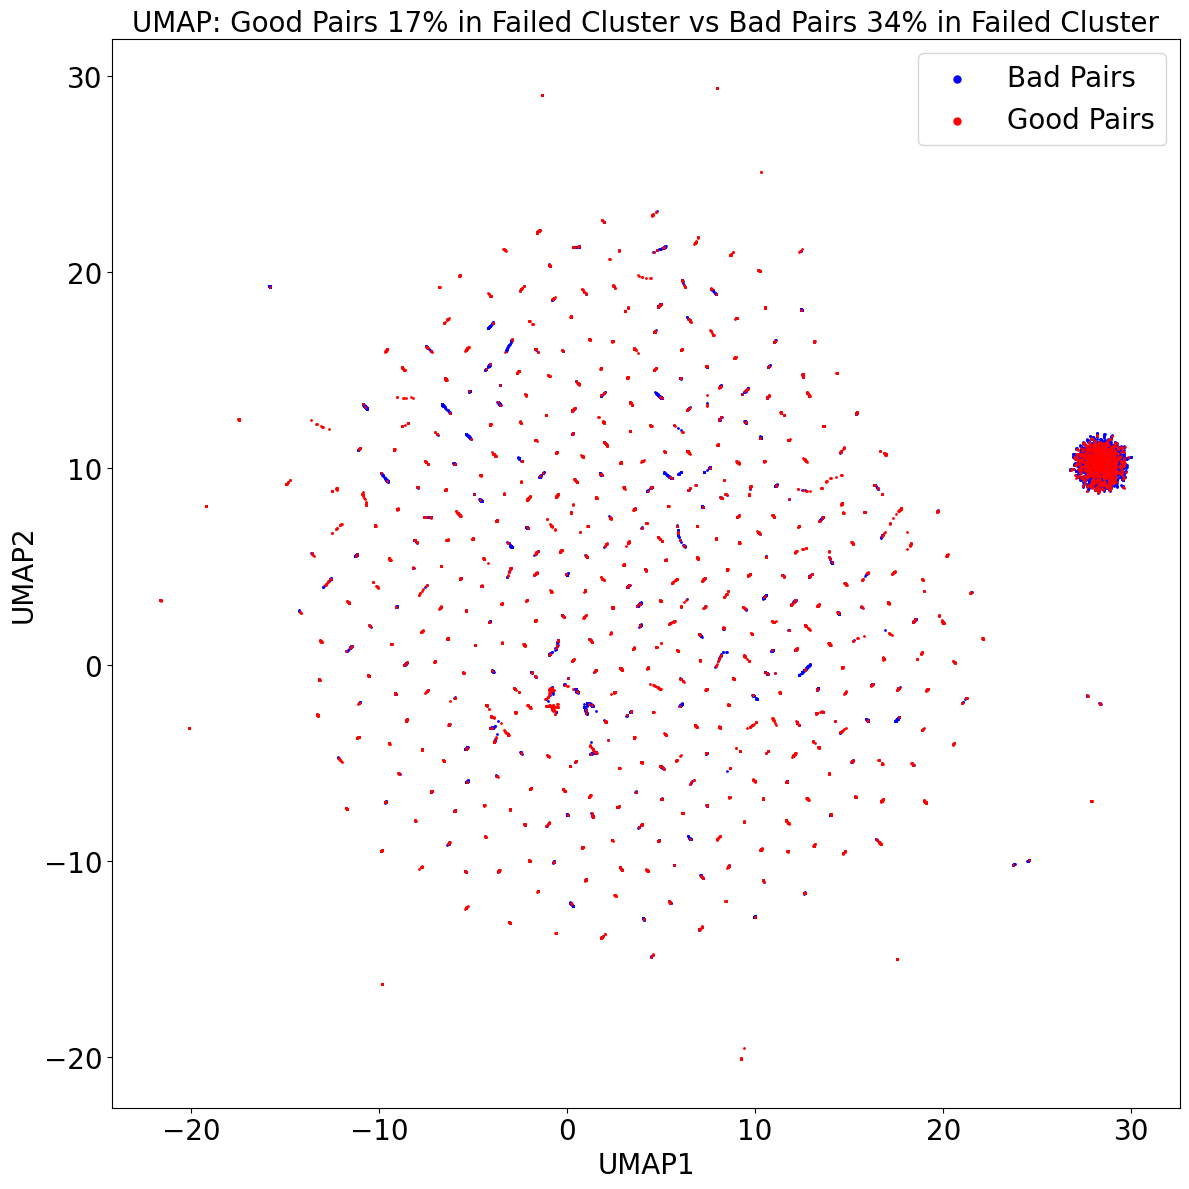

In [37]:
fig, ax = plt.subplots(figsize=(12,12))
ax.scatter(embedding[bad_mask, 0], embedding[bad_mask, 1], c='blue', s=1, alpha=1, label='Bad Pairs')
ax.scatter(embedding[good_mask, 0], embedding[good_mask, 1], c='red', s=1, alpha=1, label='Good Pairs')

ax.set_xlabel('UMAP1', fontsize=20)
ax.set_ylabel('UMAP2', fontsize=20)
ax.set_title(f'UMAP: Good Pairs {round(good_pct_in_big)}% in Failed Cluster vs Bad Pairs {round(bad_pct_in_big)}% in Failed Cluster', fontsize=20)

ax.legend(markerscale=5, fontsize=20)

ax.tick_params(axis='both', labelsize=20)
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure12_pairs.pdf')
plt.show()

reference
N01    35.714286
N02    46.666667
N03    53.333333
P01     7.142857
P02    50.000000
P03    21.428571
P04    15.384615
P05    12.500000
P06     0.000000
P07    14.285714
P08    27.272727
P09    14.285714
P10    20.000000
P11    28.571429
P12    23.076923
P13    16.666667
P14    16.666667
P15     6.250000
P16    50.000000
P17    25.000000
P18    31.250000
P19    14.285714
P20     5.882353
P21    16.666667
P22     7.142857
P23     7.692308
P24    50.000000
P25    14.285714
P26    15.384615
P27    62.500000
P28    33.333333
P29     0.000000
P30     0.000000
P31     0.000000
P32     0.000000
P33    46.153846
P34    18.181818
P35    35.714286
P36    13.333333
P37    31.578947
P38     0.000000
P39    20.000000
P40    14.285714
Name: in_cluster, dtype: float64
reference
P27    62.500000
N03    53.333333
P24    50.000000
P02    50.000000
P16    50.000000
N02    46.666667
P33    46.153846
N01    35.714286
P35    35.714286
P28    33.333333
P37    31.578947
P18    31.250000
P11    28.57

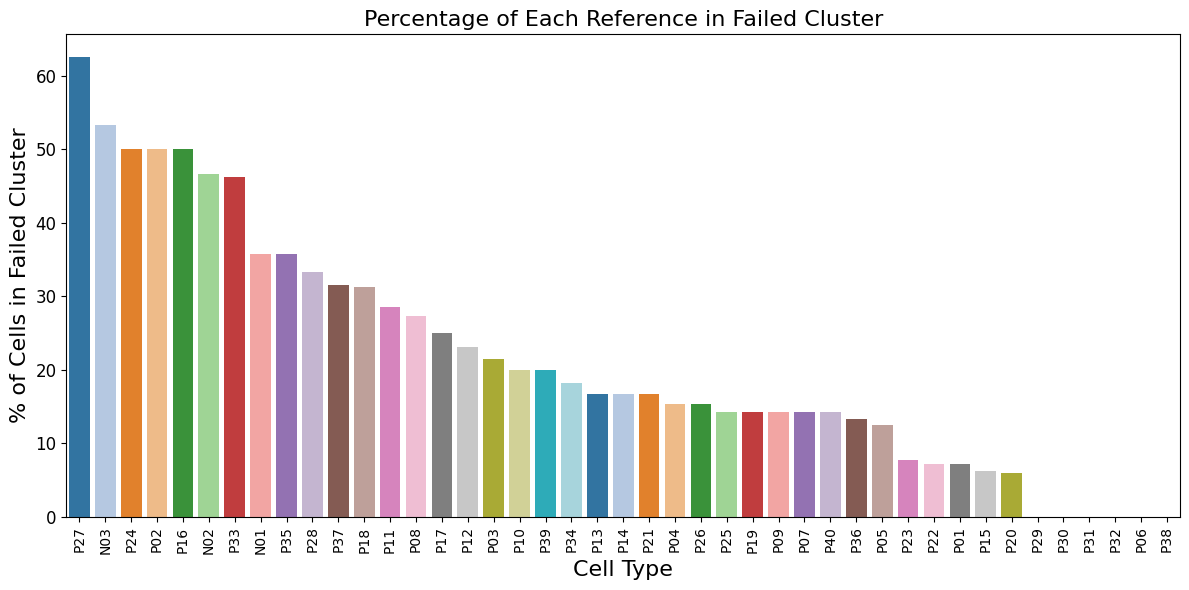

In [38]:
df_check = pd.DataFrame({'reference': single_cell_ref.values, 'in_cluster': biggest_cluster_mask})
percentage_ref = df_check.groupby('reference')['in_cluster'].mean() * 100
print(percentage_ref)

percentage_ref = percentage_ref.sort_values(ascending=False)
print(percentage_ref)
plt.figure(figsize=(12, 6))
sns.barplot(x=percentage_ref.index, y=percentage_ref.values, hue=percentage_ref.index, dodge=False, palette='tab20', legend=False)
plt.ylabel('% of Cells in Failed Cluster', fontsize=16, fontname='DejaVu Sans')
plt.xlabel('Cell Type', fontsize=16, fontname='DejaVu Sans')
plt.title('Percentage of Each Reference in Failed Cluster', fontsize=16, fontname='DejaVu Sans')
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure16_barrefbc.pdf')
plt.show()

In [39]:
df_check = pd.DataFrame({'pat_id': pat_ids.values, 'in_cluster': biggest_cluster_mask})
percentage = df_check.groupby('pat_id')['in_cluster'].mean() * 100
print(percentage)

pat_id
2014    22.184874
2015    22.184874
2016    22.184874
2017    22.184874
2029    22.184874
          ...    
2538    22.184874
2540    22.184874
2558    22.184874
2562    22.184874
2577    22.184874
Name: in_cluster, Length: 137, dtype: float64


cell_type
Neutrolphil_B_ELANE_high    61.290323
AML_progenitor_cell         48.837209
Basophil_Precursor          47.619048
Promonocyte_RPLP1_high      41.666667
Promonocyte_EEF1A1_high     33.333333
Monocyte_S100A10_high       29.411765
Monocyte_LYZ_high           27.777778
Promonocyte_TRH_high        25.000000
Erythroblast                23.076923
Proliferating_Cell          22.222222
Neutrolphil_DEFA4_high      20.000000
B_Cell_IGHG1_high           19.047619
T_Cell                      16.666667
Neutrolphil_B_AZU1_high     16.666667
B_Cell_IGHA1_high           14.285714
Erythroid_Cell_CA1_high     10.000000
Monocyte_CST3_high           6.976744
Neutrolphil_A                4.761905
Neutrolphil_C                0.000000
Erythroid_Cell_HBD_high      0.000000
Name: in_cluster, dtype: float64


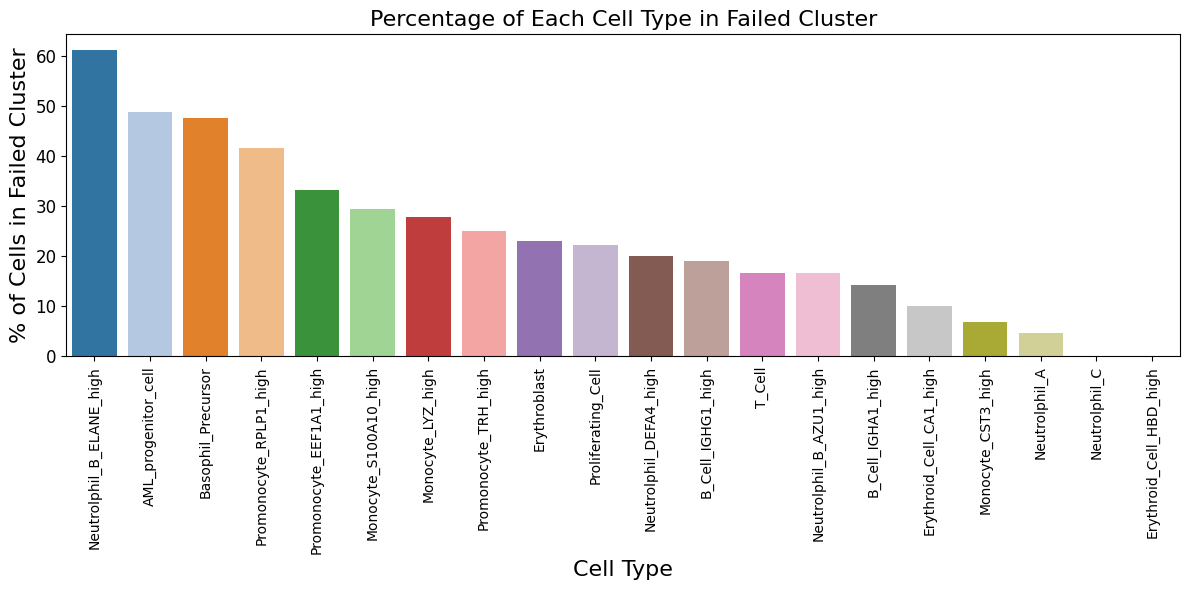

In [40]:
df_check = pd.DataFrame({'cell_type': cell_types.values, 'in_cluster': biggest_cluster_mask})
percentage = df_check.groupby('cell_type')['in_cluster'].mean() * 100

percentage = percentage.sort_values(ascending=False)
print(percentage)
plt.figure(figsize=(12, 6))
sns.barplot(x=percentage.index, y=percentage.values, hue=percentage.index, dodge=False, palette='tab20', legend=False)
plt.ylabel('% of Cells in Failed Cluster', fontsize=16, fontname='DejaVu Sans')
plt.xlabel('Cell Type', fontsize=16, fontname='DejaVu Sans')
plt.title('Percentage of Each Cell Type in Failed Cluster', fontsize=16, fontname='DejaVu Sans')
plt.xticks(rotation=90, fontsize=10, fontname='DejaVu Sans')
plt.yticks(fontsize=12)
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure13_barcelltypebc.pdf')
plt.show()

Progenitor High in cluster: 18.53%
Progenitor Low in cluster: 22.69%
Progenitor Normal in cluster: 45.45%


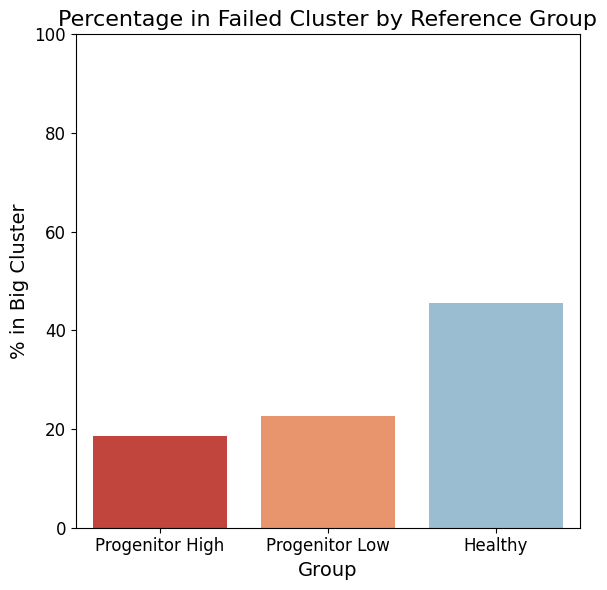

In [41]:
# Count total per group
total_high = high_mask.sum()
total_low = low_mask.sum()
total_mid = mid_mask.sum()

# Count how many from each are in the big cluster
in_cluster_high = (high_mask & biggest_cluster_mask).sum()
in_cluster_low  = (low_mask & biggest_cluster_mask).sum()
in_cluster_mid  = (mid_mask & biggest_cluster_mask).sum()

# Calculate percentages
pct_high = in_cluster_high / total_high * 100
pct_low = in_cluster_low / total_low * 100
pct_mid = in_cluster_mid / total_mid * 100

print(f"Progenitor High in cluster: {pct_high:.2f}%")
print(f"Progenitor Low in cluster: {pct_low:.2f}%")
print(f"Progenitor Normal in cluster: {pct_mid:.2f}%")

df_bar = pd.DataFrame({
    'group': ['Progenitor High', 'Progenitor Low', 'Healthy'],
    'percentage': [pct_high, pct_low, pct_mid]
})
palette = {
    'Progenitor High': '#d73027',  # red
    'Progenitor Low': '#fc8d59',   # orange
    'Healthy': '#91bfdb'           # blue
}

plt.figure(figsize=(6, 6))
sns.barplot(data=df_bar, x='group', y='percentage', hue='group', palette=palette, legend=False)
plt.ylabel('% in Big Cluster', fontsize=14)
plt.xlabel('Group', fontsize=14)
plt.title('Percentage in Failed Cluster by Reference Group', fontsize=16)
plt.ylim(0, 100)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

In [42]:
big_cluster_data = full_data[full_data.columns[biggest_cluster_mask]]

cell_type
AML_progenitor_cell         15.909091
Basophil_Precursor          15.151515
Neutrolphil_B_ELANE_high    14.393939
Monocyte_S100A10_high        7.575758
Proliferating_Cell           6.060606
B_Cell_IGHG1_high            6.060606
Neutrolphil_B_AZU1_high      5.303030
Erythroblast                 4.545455
B_Cell_IGHA1_high            4.545455
Promonocyte_EEF1A1_high      3.787879
Monocyte_LYZ_high            3.787879
Promonocyte_RPLP1_high       3.787879
Monocyte_CST3_high           2.272727
Neutrolphil_A                1.515152
Erythroid_Cell_CA1_high      1.515152
Promonocyte_TRH_high         1.515152
Neutrolphil_DEFA4_high       1.515152
T_Cell                       0.757576
Name: proportion, dtype: float64


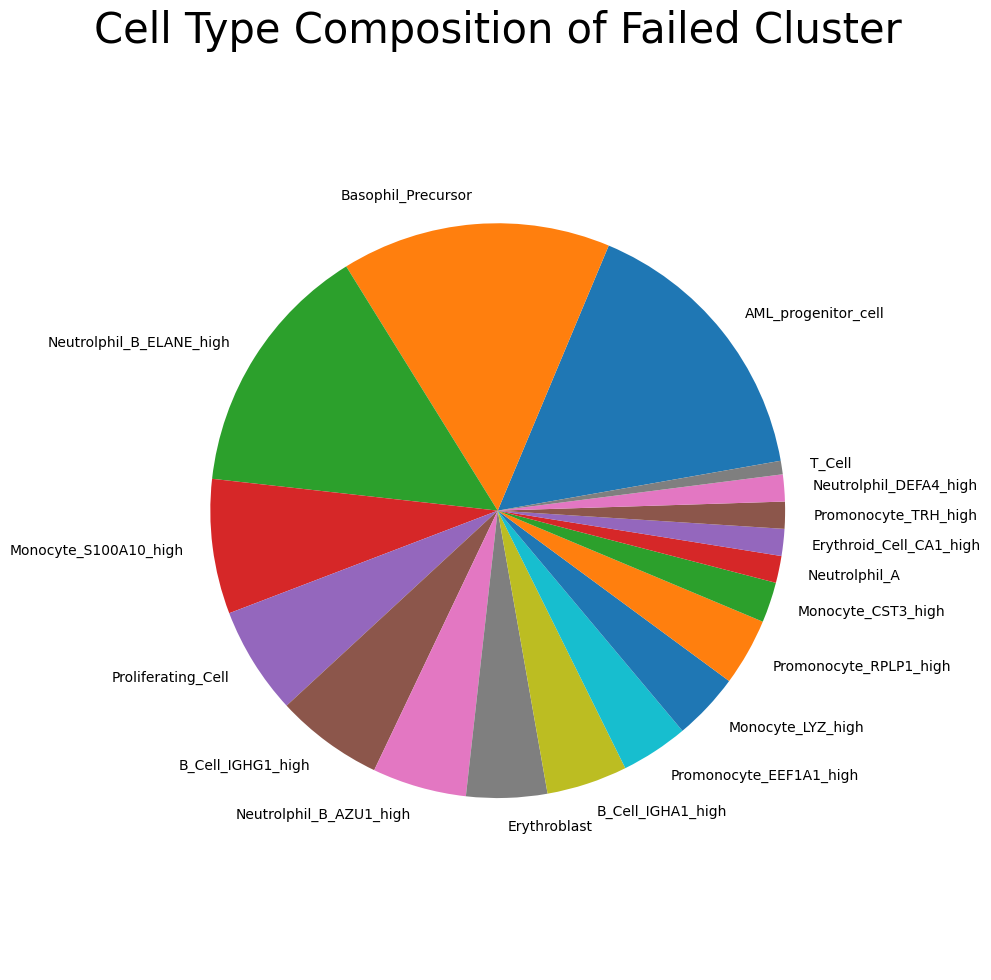

In [44]:
# Subset to only the cells in the big cluster
cluster_cell_types = cell_types[biggest_cluster_mask]
composition = cluster_cell_types.value_counts(normalize=True) * 100
composition = composition.sort_values(ascending=False)

print(composition)
fig, ax = plt.subplots(figsize=(10, 10))
ax.pie(
    composition,
    labels=composition.index,
    startangle=10,
    labeldistance=1.1,    
    textprops={'fontsize': 10}
)
ax.set_title('Cell Type Composition of Failed Cluster', fontsize=30)
ax.axis('equal')  # Equal aspect ratio ensures pie is circular.
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure15_piebc.pdf')
plt.show()

In [45]:
failure_rank = DataFrame(percentage_ref.rank())
dist_rank = DataFrame(dist_df.mean(axis=1).sort_values().rank())
num_rank = pd.read_csv(NUM_OF_CELLS,index_col = 0).rank(ascending=False)

progen_annot = full_annot[full_annot.cell_type == 'AML_progenitor_cell']

list_var = []

for i in percentage_ref.index:
    worst_annot = progen_annot[progen_annot.single_cell_reference == i]
    worst_df = DataFrame([full_data[worst_annot.index].var(axis=1).sort_values().max()], index=[i], columns=['max_var'])
    list_var.append(worst_df)

var_df = pd.concat(list_var)

In [46]:
corr_rank = pd.concat([failure_rank, dist_rank], axis=1)
corr_rank.columns = ['failure_rank', 'dist_rank']
corr_rank = pd.concat([corr_rank, num_rank], axis=1)
corr_rank = pd.concat([var_df, corr_rank], axis=1)

In [47]:
stats.spearmanr(corr_rank['failure_rank'], corr_rank['max_var'])

SignificanceResult(statistic=-0.6710053027796608, pvalue=8.472257484143247e-07)

In [48]:
stats.spearmanr(corr_rank['dist_rank'], corr_rank['max_var'])

SignificanceResult(statistic=-0.5895481994489374, pvalue=3.184654608489183e-05)

In [49]:
stats.spearmanr(corr_rank['failure_rank'], corr_rank['dist_rank'])

SignificanceResult(statistic=0.5510028692525191, pvalue=0.00012868406300281732)

In [50]:
stats.spearmanr(corr_rank['failure_rank'], corr_rank['Total'])

SignificanceResult(statistic=-0.1588892736036595, pvalue=0.3088262568714433)

In [51]:
stats.spearmanr(corr_rank['failure_rank'], corr_rank['AML_progenitor_cell'])

SignificanceResult(statistic=0.08674945571690987, pvalue=0.5801700992993841)

In [55]:
bulk_data = pd.read_csv(BULK_MATRIX, sep='\t', index_col=0).drop(['AML1', 'AML2', 'AML3'], axis=1)
bulk_data.columns = ["Bulk_" + col.split('_')[0] for col in bulk_data.columns]

In [56]:
#P38, P14, P30, P23  good selection based on dist_df and failure rate
#P34, P25, P20, P36  bad selection based on dist_df and failure rate
select_pat = ['P38', 'P14', 'P30', 'P23', 'P34', 'P25', 'P20', 'P36']
select_annot = progen_annot[progen_annot['single_cell_reference'].isin(select_pat)]
select_data = full_data[select_annot.index]
select_data.columns = [scol.split('_')[1] + '_' + scol.split('_')[0] for scol in select_data.columns]

In [57]:
select_final = pd.concat([bulk_data, select_data], axis=1).fillna(0)

In [58]:
select_final = select_final.rename_axis('genes')
proj = 'deconvalid'

In [62]:
progen_data = full_data[progen_annot.index]

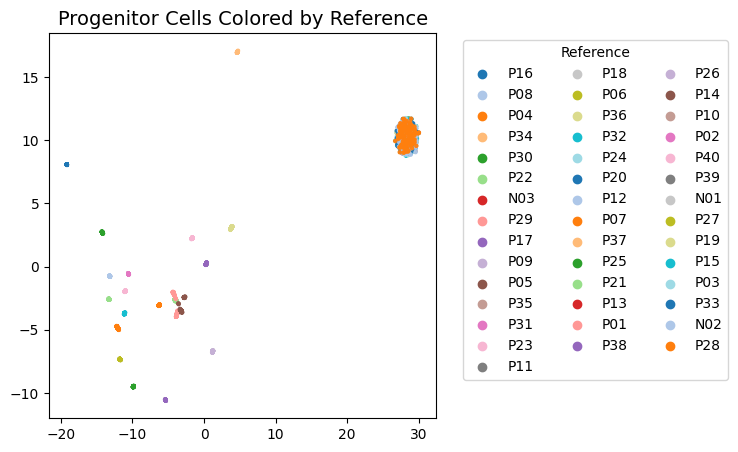

In [63]:
progen_mask = full_annot['cell_type'] == 'AML_progenitor_cell'
subset_annot = full_annot[progen_mask]
subset_embedding = embedding[progen_mask]

unique_refs = subset_annot['single_cell_reference'].unique()
palette = sns.color_palette('tab20', n_colors=len(unique_refs))
lut = dict(zip(unique_refs, palette))
colors = subset_annot['single_cell_reference'].map(lut).values

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(subset_embedding[:, 0], subset_embedding[:, 1], c=colors, s=5, alpha=0.9)

for ref in unique_refs:
    ax.scatter([], [], color=lut[ref], label=ref)

ax.set_title('Progenitor Cells Colored by Reference', fontsize=14)
ax.legend(markerscale=1, bbox_to_anchor=(1.05, 1), loc='upper left', title='Reference', ncol=3)
plt.show()

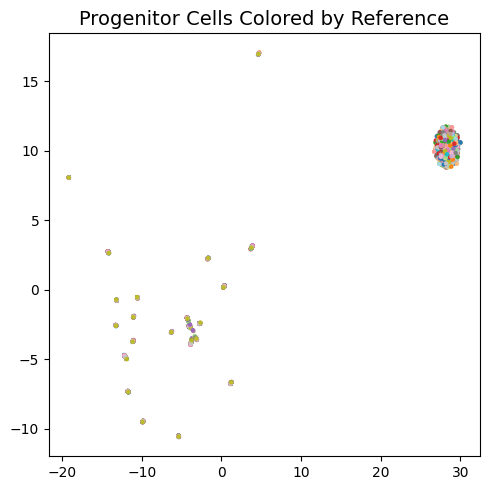

In [64]:
# Filter to progenitor cells
progen_mask = full_annot['cell_type'] == 'AML_progenitor_cell'
subset_annot = full_annot[progen_mask]
subset_embedding = embedding[progen_mask]

# Assign colors by single_cell_reference
unique_refs = subset_annot['pat_id'].unique()
palette = sns.color_palette('tab20', n_colors=len(unique_refs))
lut = dict(zip(unique_refs, palette))
colors = subset_annot['pat_id'].map(lut).values

# Plot
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(subset_embedding[:, 0], subset_embedding[:, 1], c=colors, s=5, alpha=0.9)
ax.set_title('Progenitor Cells Colored by Reference', fontsize=14)
plt.tight_layout()
plt.show()

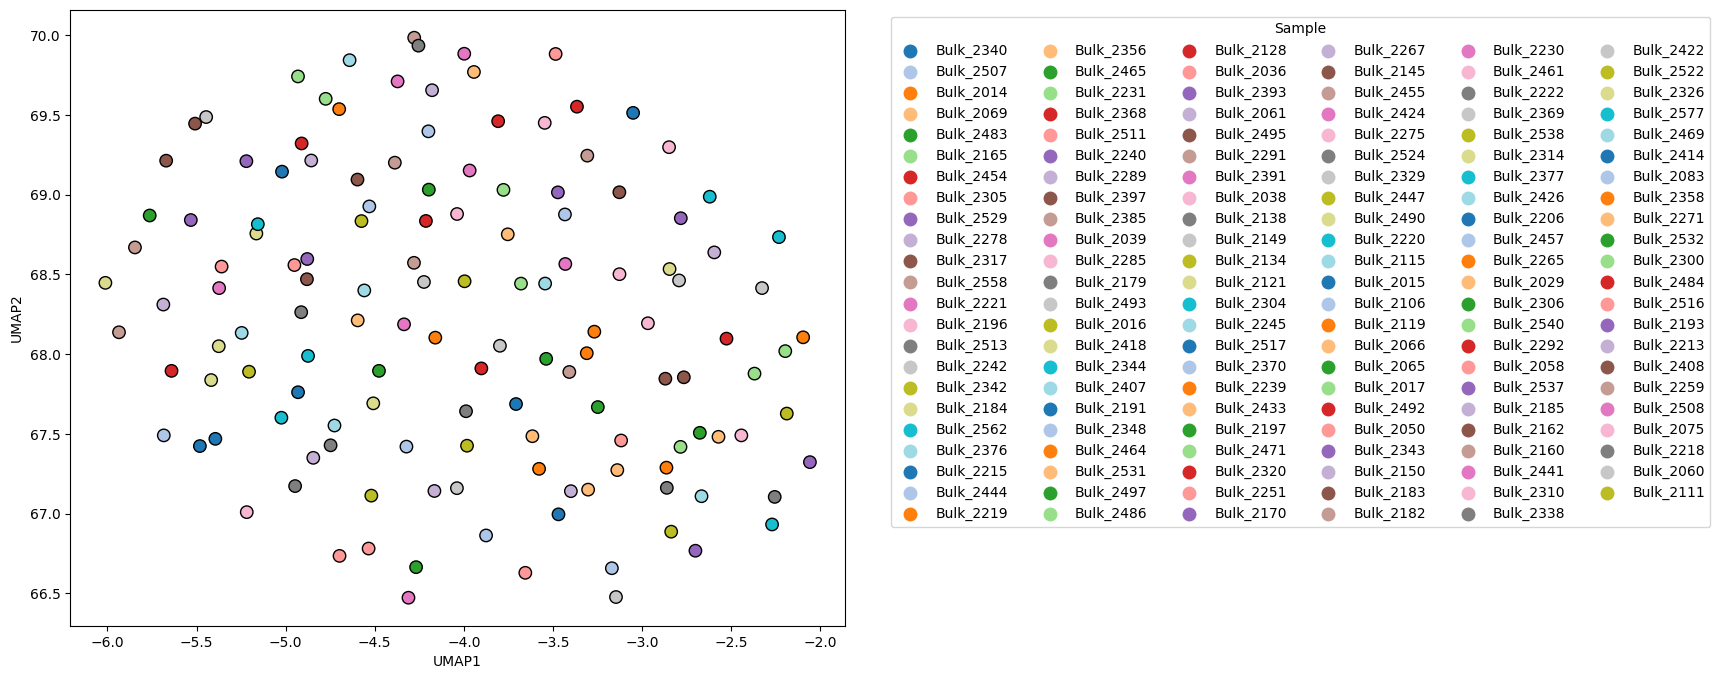

In [65]:
Y = bulk_data.T 

pca = PCA(n_components=50)
Y_pca = pca.fit_transform(Y)
reducer = umap.UMAP(n_neighbors=50, min_dist=0.1, metric='euclidean')
bulk_embedding = reducer.fit_transform(Y_pca)

sample_names = Y.index
palette = sns.color_palette('tab20', n_colors=len(sample_names))  # or more if needed
color_dict = dict(zip(sample_names, palette))
colors = sample_names.map(color_dict)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(bulk_embedding[:, 0], bulk_embedding[:, 1], c=colors, s=80, edgecolor='black')

for name in sample_names:
    ax.scatter([], [], color=color_dict[name], label=name)
ax.legend(markerscale=1.5, bbox_to_anchor=(1.05, 1), loc='upper left', title='Sample', ncol=6)
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')
plt.show()

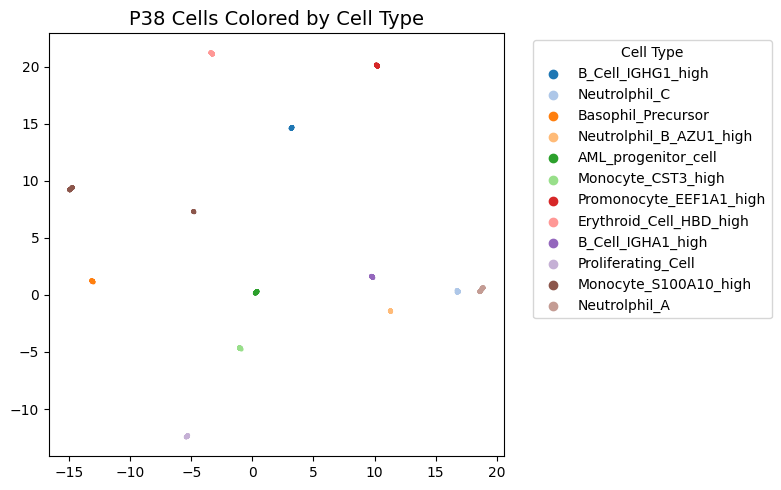

In [66]:
singleref_mask = full_annot['single_cell_reference'] == 'P38'
singleref_annot = full_annot[singleref_mask]
singleref_embedding = embedding[singleref_mask]

unique_refs = singleref_annot['cell_type'].unique()
palette = sns.color_palette('tab20', n_colors=len(unique_refs))
lut = dict(zip(unique_refs, palette))
colors = singleref_annot['cell_type'].map(lut).values

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(singleref_embedding[:, 0], singleref_embedding[:, 1], c=colors, s=5, alpha=0.9)

for ct in unique_refs:
    ax.scatter([], [], color=lut[ct], label=ct)

ax.set_title('P38 Cells Colored by Cell Type', fontsize=14)
ax.legend(markerscale=1, bbox_to_anchor=(1.05, 1), loc='upper left', title='Cell Type')
plt.tight_layout()
plt.show()

In [68]:
stats.spearmanr(corr_rank['failure_rank'], corr_rank['dist_rank'])

SignificanceResult(statistic=0.5510028692525191, pvalue=0.00012868406300281732)

In [69]:
stats.spearmanr(corr_rank['max_var'], corr_rank['dist_rank'])

SignificanceResult(statistic=-0.5895481994489373, pvalue=3.1846546084891946e-05)

In [70]:
stats.spearmanr(corr_rank['max_var'], corr_rank['failure_rank'])

SignificanceResult(statistic=-0.6710053027796608, pvalue=8.472257484143247e-07)

In [71]:
stats.spearmanr(corr_rank['AML_progenitor_cell'], corr_rank['failure_rank'])

SignificanceResult(statistic=0.08674945571690985, pvalue=0.5801700992993841)

In [72]:
stats.spearmanr(corr_rank['AML_progenitor_cell'], corr_rank['max_var'])

SignificanceResult(statistic=-0.18345069312552764, pvalue=0.23897827081383105)

In [73]:
stats.spearmanr(corr_rank['AML_progenitor_cell'], corr_rank['dist_rank'])

SignificanceResult(statistic=0.30836605255209903, pvalue=0.04423789625609778)

In [75]:
failure_rank = DataFrame(percentage_ref.rank())
dist_rank = DataFrame(dist_df.mean(axis=1).sort_values().rank())

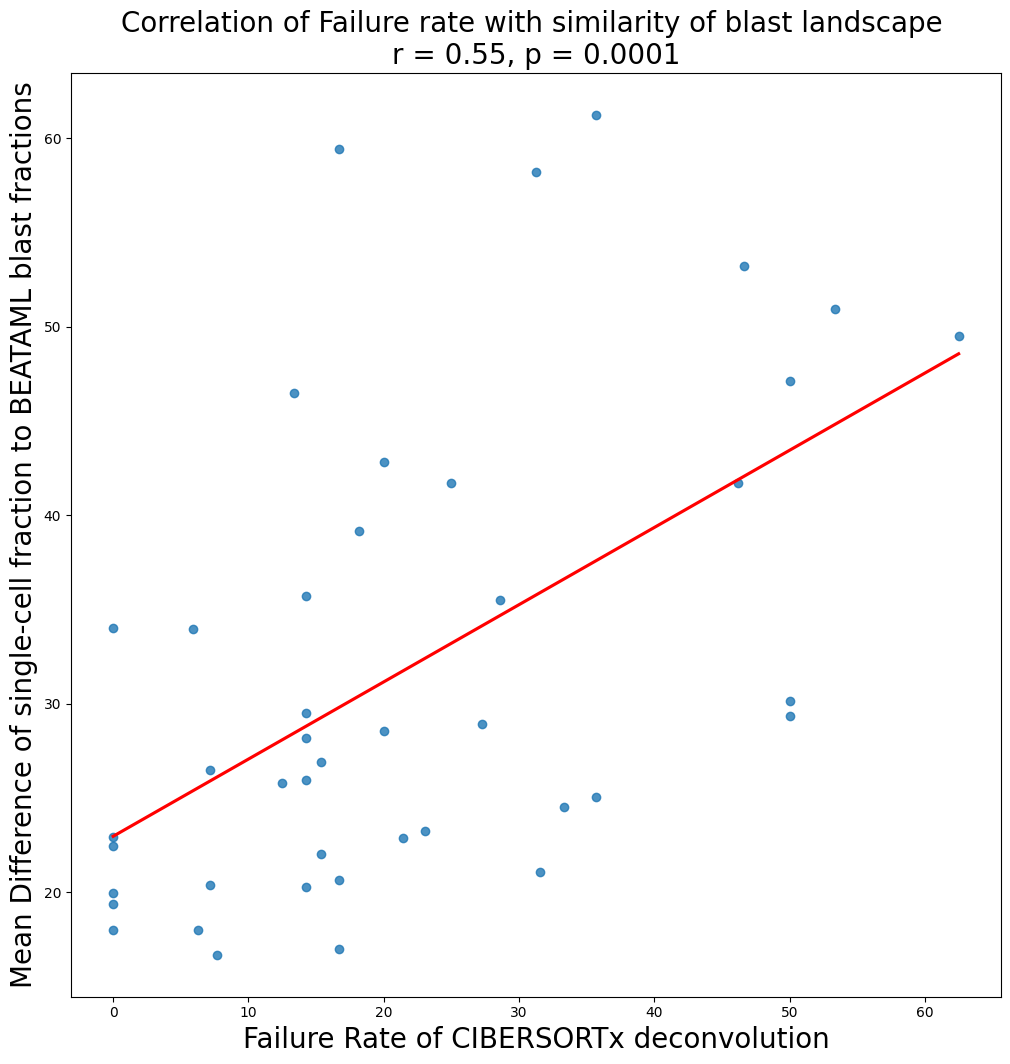

In [76]:
plot_failure_dist = pd.concat([DataFrame(percentage_ref), DataFrame(dist_df.mean(axis=1))], axis=1)
plot_failure_dist.columns=['Failure Rate', 'Distance']

r, p = stats.spearmanr(plot_failure_dist['Failure Rate'], plot_failure_dist['Distance'])

plt.figure(figsize=(12, 12))
sns.regplot(x=plot_failure_dist['Failure Rate'], y=plot_failure_dist['Distance'], data=plot_failure_dist, scatter=True, ci=None, line_kws={'color': 'red'})
plt.title(f'Correlation of Failure rate with similarity of blast landscape \nr = {r:.2f}, p = {p:.4f}', fontsize=20, fontname='DejaVu Sans')
plt.xlabel('Failure Rate of CIBERSORTx deconvolution', fontsize=20, fontname='DejaVu Sans')
plt.ylabel('Mean Difference of single-cell fraction to BEATAML blast fractions', fontsize=20, fontname='DejaVu Sans')
plt.savefig(f'{FIGURE_DIR}/figure_corr_failure_frac.pdf')
plt.savefig(f'{FIGURE_DIR}/figure_corr_failure_frac.svg')
plt.show()

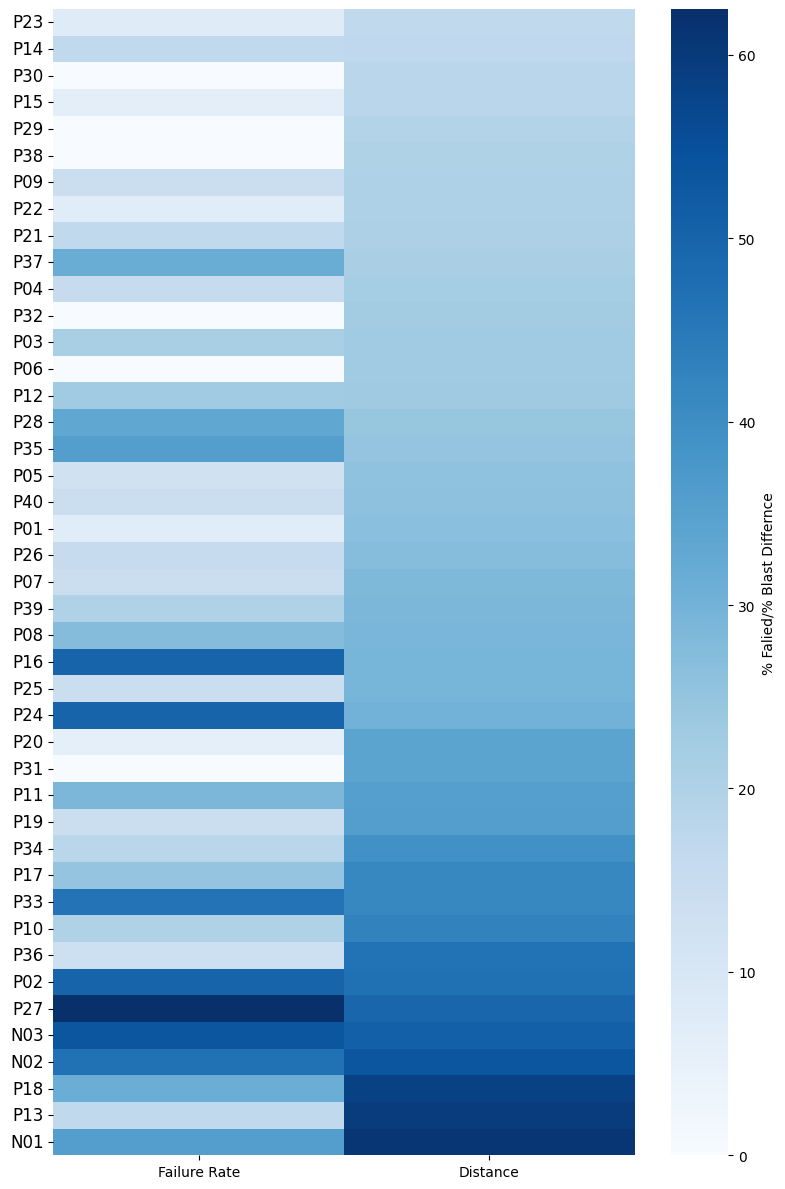

In [77]:
plt.figure(figsize=(8, 12))  # Adjust width and height as needed
ax = sns.heatmap(plot_failure_dist.sort_values('Distance'), cmap='Blues', cbar_kws={'label': '% Falied/% Blast Differnce'})

ax.set_yticklabels(ax.get_yticklabels(), fontsize=12, rotation=0, fontname='DejaVu Sans')
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure_failure_frac_heatmap.pdf')
plt.show()

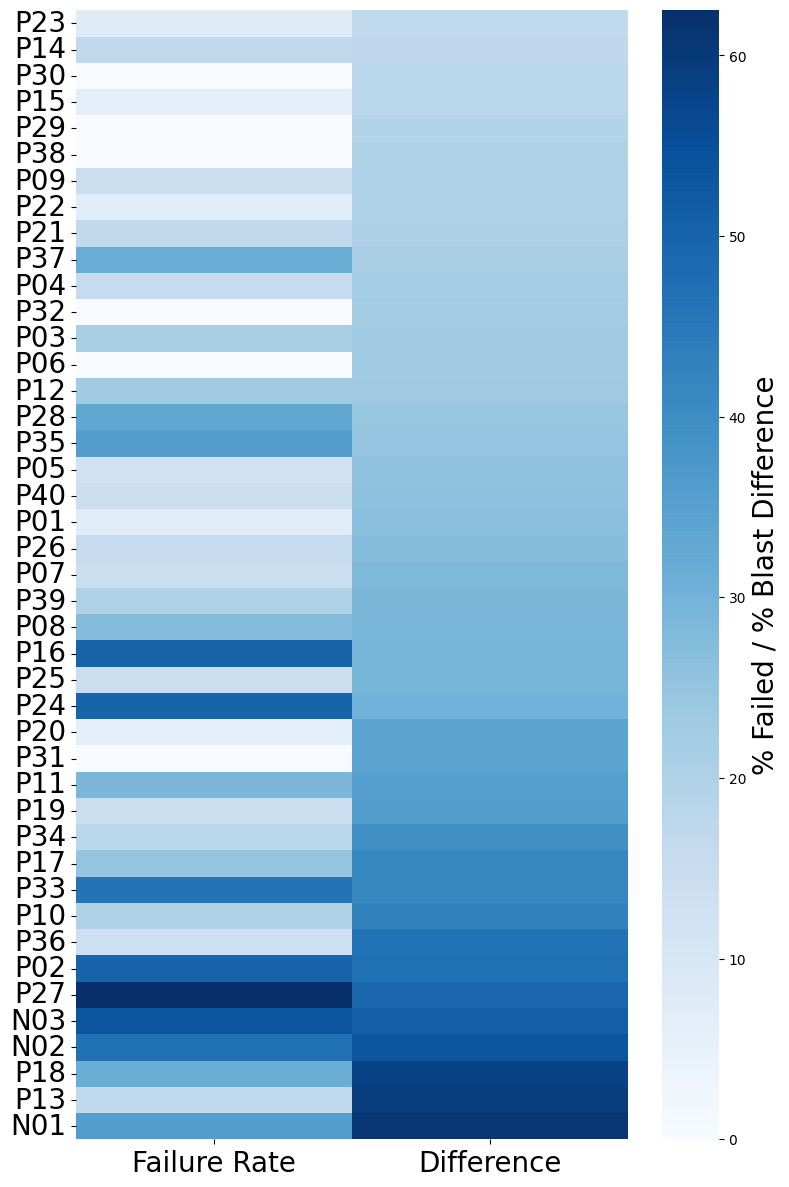

In [80]:
plt.figure(figsize=(8, 12))
plot_failure_diff = plot_failure_dist.rename(columns={'Distance': 'Difference'})

ax = sns.heatmap(plot_failure_diff.sort_values('Difference'), cmap='Blues', cbar_kws={'label': '% Failed / % Blast Difference'})

ax.set_yticklabels(ax.get_yticklabels(), fontsize=20, rotation=0, fontname='DejaVu Sans')
ax.set_xticklabels(ax.get_xticklabels(), fontsize=20, rotation=0, fontname='DejaVu Sans')

ax.figure.axes[-1].set_ylabel('% Failed / % Blast Difference', fontsize=20, fontname='DejaVu Sans')

plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure_failure_frac_heatmap.svg')
plt.show()

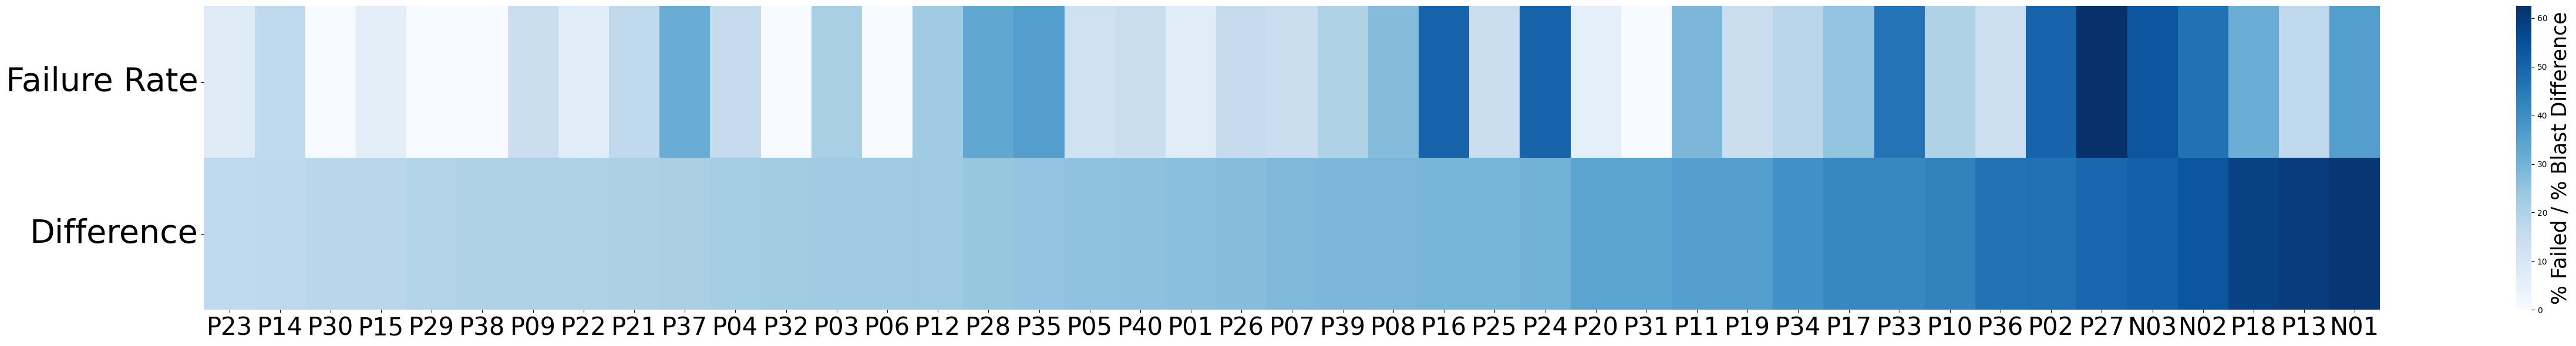

In [95]:
plt.figure(figsize=(50, 6))
plot_failure_diff = plot_failure_dist.rename(columns={'Distance': 'Difference'})

ax = sns.heatmap(plot_failure_diff.sort_values('Difference').T, cmap='Blues', cbar_kws={'label': '% Failed / % Blast Difference'})

ax.set_yticklabels(ax.get_yticklabels(), fontsize=40, rotation=0, fontname='DejaVu Sans')
ax.set_xticklabels(ax.get_xticklabels(), fontsize=30, rotation=0, fontname='DejaVu Sans')

ax.figure.axes[-1].set_ylabel('% Failed / % Blast Difference', fontsize=25, fontname='DejaVu Sans')

plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/figure_failure_frac_heatmap.svg')
plt.show()

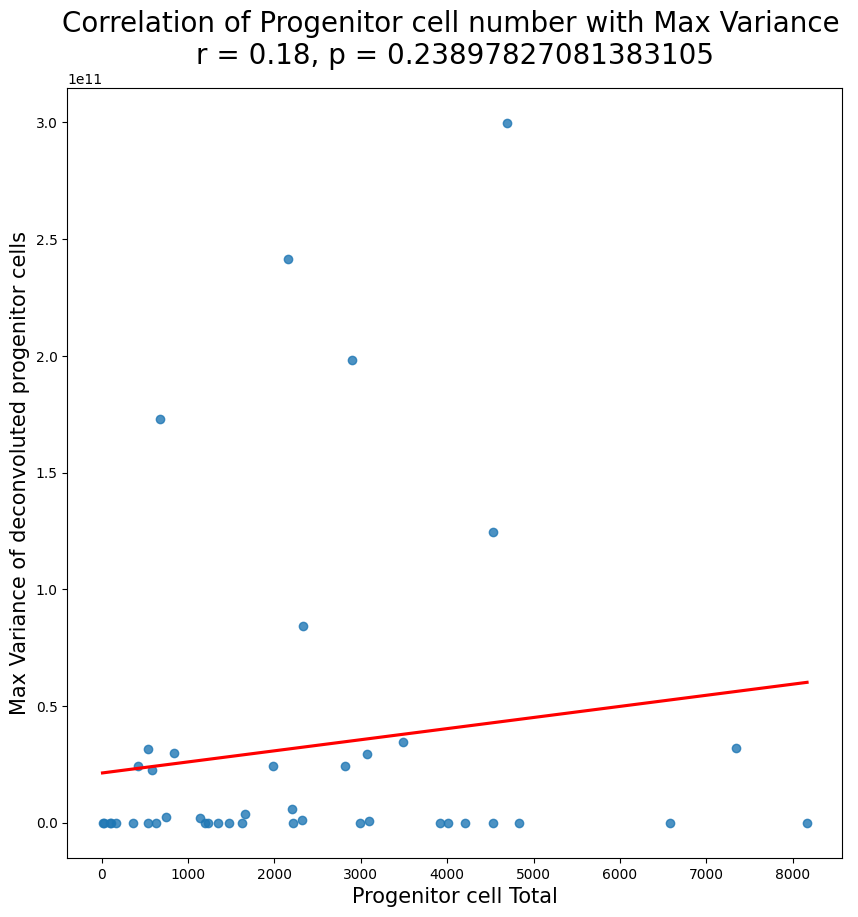

In [78]:
num_num_cells = pd.read_csv(NUM_OF_CELLS,index_col = 0)

plot_var_num = pd.concat([DataFrame(num_num_cells['AML_progenitor_cell']), DataFrame(var_df)], axis=1)
plot_var_num.columns=['Progenitor cell number', 'Max Variance']

r, p = stats.spearmanr(plot_var_num['Progenitor cell number'], plot_var_num['Max Variance'])

plt.figure(figsize=(10, 10))
sns.regplot(x=plot_var_num['Progenitor cell number'], y=plot_var_num['Max Variance'], data=plot_var_num, scatter=True, ci=None, line_kws={'color': 'red'})
plt.title(f'Correlation of Progenitor cell number with Max Variance \nr = {r:.2f}, p = {p}', fontsize=20)
plt.xlabel('Progenitor cell Total', fontsize=15)
plt.ylabel('Max Variance of deconvoluted progenitor cells', fontsize=15)
plt.savefig(f'{FIGURE_DIR}/figure_var_frac.pdf')
plt.show()

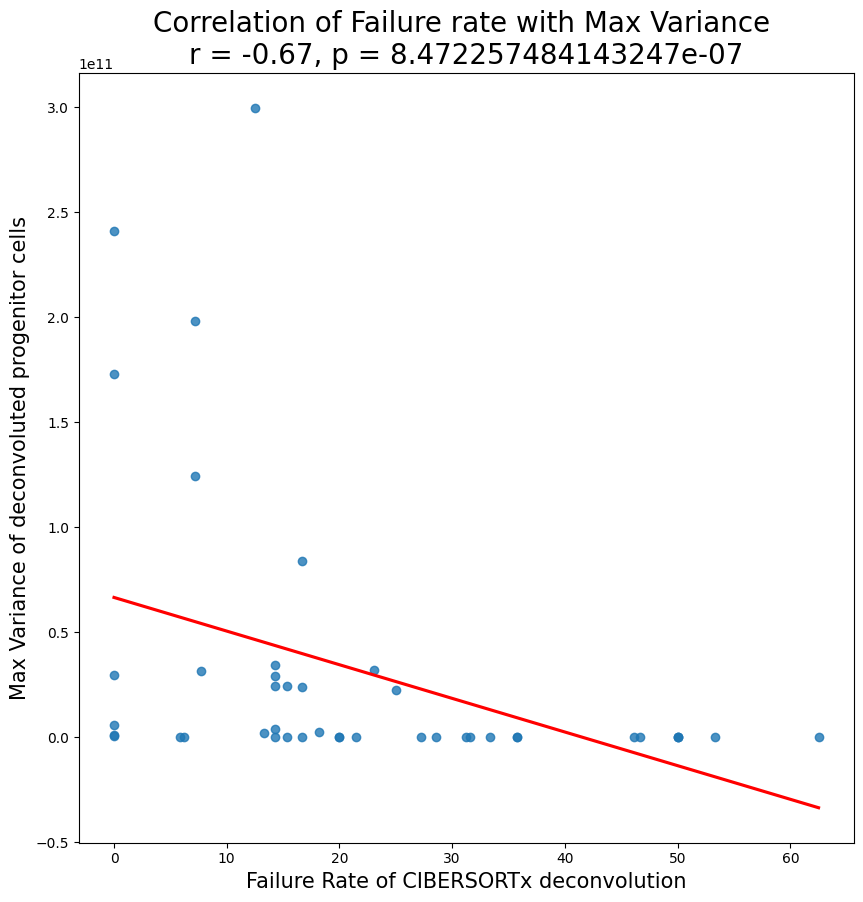

In [79]:
plot_failure_var = pd.concat([DataFrame(percentage_ref), DataFrame(var_df)], axis=1)
plot_failure_var.columns=['Failure Rate', 'Max Variance']

r, p = stats.spearmanr(plot_failure_var['Failure Rate'], plot_failure_var['Max Variance'])

plt.figure(figsize=(10, 10))
sns.regplot(x=plot_failure_var['Failure Rate'], y=plot_failure_var['Max Variance'], data=plot_failure_var, scatter=True, ci=None, line_kws={'color': 'red'})
plt.title(f'Correlation of Failure rate with Max Variance \nr = {r:.2f}, p = {p}', fontsize=20)
plt.xlabel('Failure Rate of CIBERSORTx deconvolution', fontsize=15)
plt.ylabel('Max Variance of deconvoluted progenitor cells', fontsize=15)
plt.savefig(f'{FIGURE_DIR}/figure_var_failure.pdf')
plt.show()

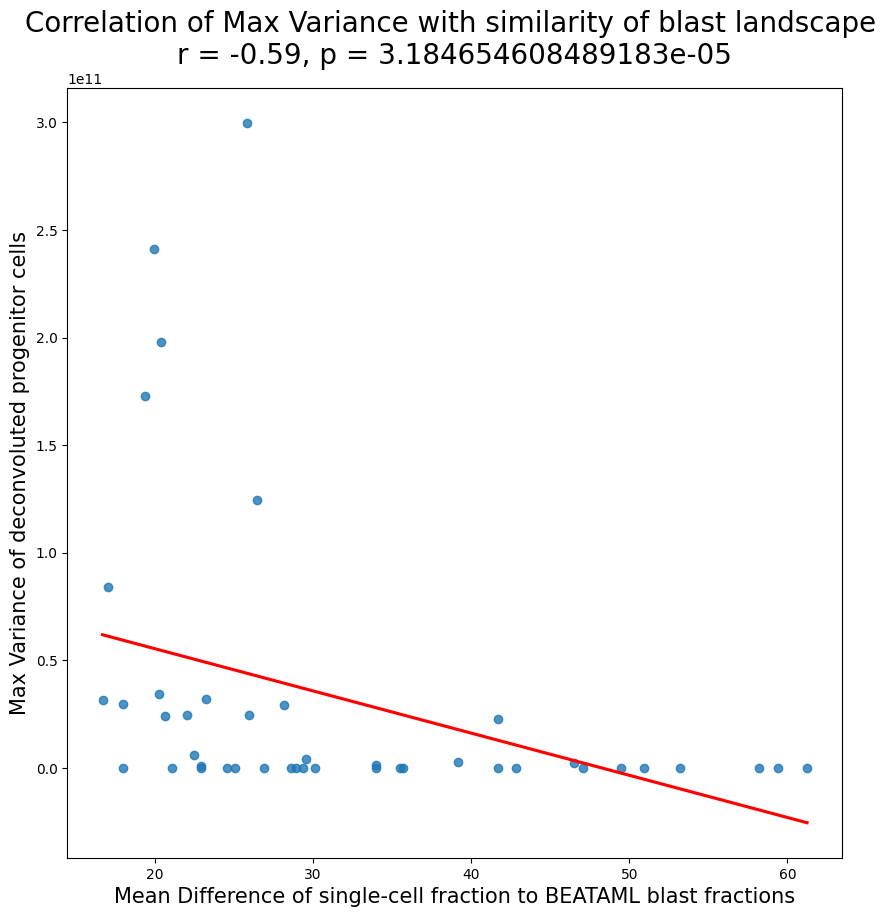

In [82]:
plot_dist_var = pd.concat([DataFrame(dist_df.mean(axis=1)), DataFrame(var_df)], axis=1)
plot_dist_var.columns=['Distance', 'Max Variance']

r, p = stats.spearmanr(plot_dist_var['Distance'], plot_dist_var['Max Variance'])

plt.figure(figsize=(10, 10))
sns.regplot(x=plot_dist_var['Distance'], y=plot_dist_var['Max Variance'], data=plot_dist_var, scatter=True, ci=None, line_kws={'color': 'red'})
plt.title(f'Correlation of Max Variance with similarity of blast landscape \nr = {r:.2f}, p = {p}', fontsize=20)
plt.xlabel('Mean Difference of single-cell fraction to BEATAML blast fractions', fontsize=15)
plt.ylabel('Max Variance of deconvoluted progenitor cells', fontsize=15)
plt.savefig(f'{FIGURE_DIR}/figure_dist_var.pdf')
plt.show()

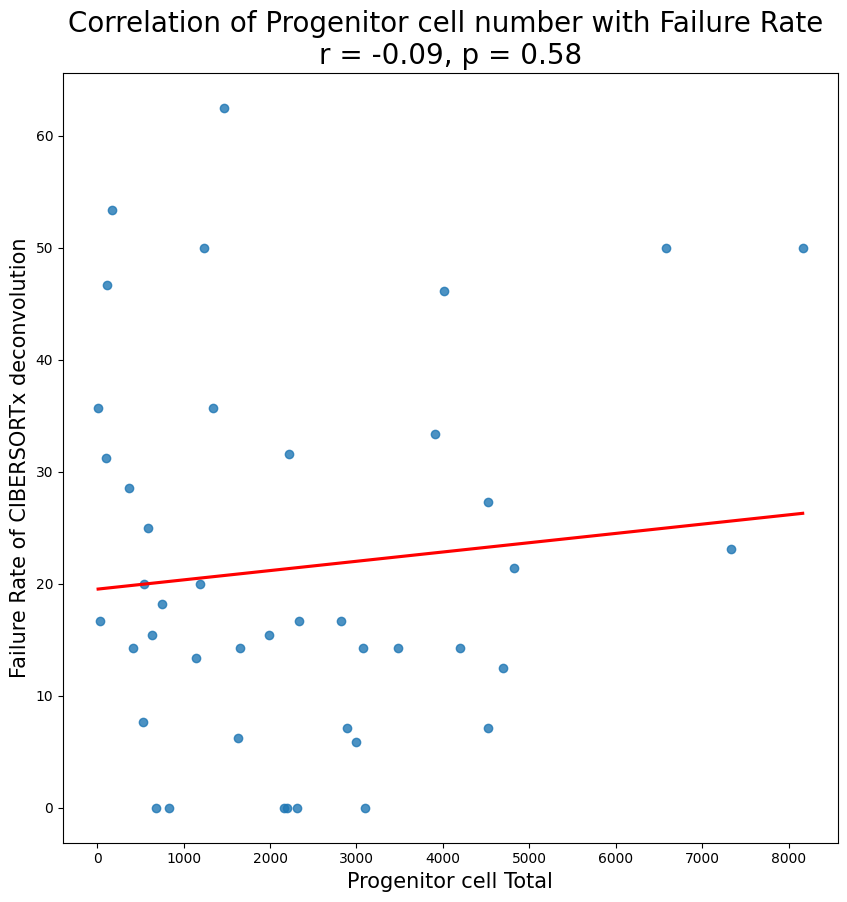

In [81]:
plot_fail_num = pd.concat([DataFrame(num_num_cells['AML_progenitor_cell']), DataFrame(percentage_ref)], axis=1)
plot_fail_num.columns=['Progenitor cell number', 'Failure Rate']

r, p = stats.spearmanr(plot_fail_num['Progenitor cell number'], plot_fail_num['Failure Rate'])

plt.figure(figsize=(10, 10))
sns.regplot(x=plot_fail_num['Progenitor cell number'], y=plot_fail_num['Failure Rate'], data=plot_fail_num, scatter=True, ci=None, line_kws={'color': 'red'})
plt.title(f'Correlation of Progenitor cell number with Failure Rate \nr = {r:.2f}, p = {p:.2f}', fontsize=20)
plt.xlabel('Progenitor cell Total', fontsize=15)
plt.ylabel('Failure Rate of CIBERSORTx deconvolution', fontsize=15)
plt.savefig(f'{FIGURE_DIR}/figure_fail_num.pdf')
plt.show()